# Severidad de los siniestros viales en Bogotá — notebook completo
**Grupo 2 · Estadística Bayesiana · Entrega final**  
Jean Paul Rojas Rojas · Daniel Estiven Pacheco Villagrande · Diego Andrés Cascante Camacho

Este notebook reúne todo el trabajo, de la base de la Secretaría Distrital de Movilidad a cada cifra y figura del informe `Grupo2_EntregaFinal_Bayesiana.pdf`. Se ejecuta de principio a fin: **Entorno de ejecución → Ejecutar todas**.

**Índice**

0. Configuración y código común
1. Carga y limpieza de la base de la SDM
2. Análisis exploratorio descriptivo (2015–2019)
3. Del EDA al modelo: forma por celda, priors de la Primera Entrega y partición
4. Priors de M1 y M2 y chequeo predictivo a priori
5. M1: Beta-Binomial jerárquico (Gibbs + Metropolis-Hastings)
6. M2: regresión logística jerárquica (MH por componentes + Gibbs)
7. Convergencia, resultados por celda y validación con 2018–2019
8. Las cinco sensibilidades fijadas en el Avance 2
9. Comprobación final

**Antes de correrlo en Colab.** Suba la carpeta `notebooks` a su Drive. La etapa 1 necesita el Excel de la SDM (`siniestros_viales_consolidados_bogota_dc.xlsx`, 47 MB) en `notebooks/datos/`. Si no lo tiene, empiece en la etapa 2: `datos/siniestros_limpios.csv` ya viene incluido. Trazabilidad completa en `README.md`.

## 0. Configuración y código común

In [1]:
# Configuración (corre una sola vez): funciona en Google Colab y en un computador
# En Colab: suba la carpeta "notebooks" a su Drive. Si el buscador automático no la encuentra,
# escriba su ruta en BASE_COLAB, p. ej. '/content/drive/MyDrive/Grupo2_EntregaFinal_Bayesiana/notebooks'
BASE_COLAB = ''
import os, sys, glob
from pathlib import Path
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    if not BASE_COLAB:
        cand = glob.glob('/content/drive/MyDrive/**/notebooks/Grupo2_Bayesiana_completo.ipynb', recursive=True)
        assert cand, 'No encontré la carpeta notebooks en su Drive: escriba su ruta en BASE_COLAB'
        BASE_COLAB = os.path.dirname(cand[0])
    BASE = Path(BASE_COLAB)
else:
    BASE = Path.cwd()
os.chdir(BASE)
sys.path.insert(0, str(BASE))
print('Carpeta:', BASE)

Carpeta: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks


El código común (rutas, datos, celdas y métricas) y los muestreadores MCMC se escriben como módulos `comun.py` y `mcmc.py`, para que todas las etapas usen exactamente el mismo código. Los mismos algoritmos se muestran y explican en las etapas 5 y 6.

In [2]:
%%writefile comun.py
"""
Grupo 2 - Estadística Bayesiana - Entrega final
Módulo común a los notebooks 02 a 08: rutas, datos, celdas y métricas.
Es el mismo código de Grupo2_EntregaFinal_Bayesiana.py (secciones 1 y 6), separado
para que cada notebook pueda correr por sí solo.
"""
from pathlib import Path
import json

import numpy as np
import pandas as pd
from scipy import special as sp
from scipy import stats as st
import sys
import matplotlib

if "ipykernel" not in sys.modules:      # fuera de Jupyter/Colab no se abren ventanas
    matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

# ---------------------------------------------------------------- rutas
BASE = Path(__file__).resolve().parent                  # carpeta notebooks/
PROYECTO = BASE.parent.parent                           # .../Proyecto (solo en el computador del equipo)
SALIDAS = BASE / "salidas"
FIG = SALIDAS / "figuras"
RES = SALIDAS / "resultados"
DATOS = BASE / "datos"
for _c in (DATOS, FIG, RES):
    _c.mkdir(parents=True, exist_ok=True)


def ruta_datos(nombre):
    """Busca un archivo de datos en notebooks/datos/ y, si no está, en la carpeta del proyecto."""
    for d in (DATOS, PROYECTO / "0. Base de Datos" / "datos_trabajados", PROYECTO / "0. Base de Datos"):
        if (d / nombre).exists():
            return d / nombre
    raise FileNotFoundError(f"No encontré {nombre}: póngalo en {DATOS}")


SEED = 20261109
K, BURN, ITER = 4, 5000, 20000

plt.rcParams.update({"figure.dpi": 150, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
AZUL, ROJO, GRIS, NARANJA = "#1f4e79", "#c0392b", "#7f7f7f", "#e67e22"
FRANJAS = ["Madrugada (0-6)", "Mañana (6-12)", "Tarde (12-18)", "Noche (18-24)"]
SUR = ["San Cristóbal", "Rafael Uribe Uribe", "Usme", "Ciudad Bolívar", "Bosa", "Tunjuelito"]

# ---------------------------------------------------------------- datos
df = pd.read_csv(ruta_datos("siniestros_limpios.csv"),
                 usecols=["anio", "hora", "franja", "franja3h", "localidad", "grave", "con_muertos"])
LOCS = sorted(df["localidad"].unique())
FR3 = sorted(df["franja3h"].unique())
L, F = len(LOCS), len(FRANJAS)


def celdas(d, col_franja="franja", niveles=FRANJAS, y="grave"):
    """Tabla completa localidad x franja (incluye celdas con n = 0)."""
    idx = pd.MultiIndex.from_product([LOCS, niveles], names=["localidad", col_franja])
    t = d.groupby(["localidad", col_franja])[y].agg(n="size", y="sum").reindex(idx, fill_value=0)
    return t.reset_index()


tr = df[df.anio.between(2015, 2017)]
te = df[df.anio.between(2018, 2019)]
d20 = df[df.anio == 2020]
c_tr, c_te, c_20 = celdas(tr), celdas(te), celdas(d20)
n_tr, y_tr = c_tr.n.values, c_tr.y.values
n_te, y_te = c_te.n.values, c_te.y.values
es_sur = np.isin(c_tr.localidad.values, SUR)
es_noche = np.isin(c_tr.franja.values, ["Madrugada (0-6)", "Noche (18-24)"])
eleg = (n_tr >= 30) & (n_te >= 30)          # celdas que cuentan para el orden (Avance 2)
idx_e = np.where(eleg)[0]
p_cruda_tr = np.where(n_tr > 0, y_tr / np.maximum(n_tr, 1), y_tr.sum() / n_tr.sum())
p_city = np.full(L * F, y_tr.sum() / n_tr.sum())
obs_te = np.where(n_te > 0, y_te / np.maximum(n_te, 1), np.nan)

# celdas por año (para M2)
cy = (tr.groupby(["localidad", "franja", "anio"]).grave.agg(n="size", y="sum")
      .reindex(pd.MultiIndex.from_product([LOCS, FRANJAS, [2015, 2016, 2017]]), fill_value=0))
N3 = cy["n"].values.reshape(L, F, 3)
Y3 = cy["y"].values.reshape(L, F, 3)


# ---------------------------------------------------------------- métricas
def metricas(p, n=n_te, y=y_te, eleg_=eleg, theta_thin=None):
    """Brier, log-loss, Spearman, top 10, MAE por subgrupo; con theta_thin (draws ya
    adelgazados 1 de cada 20) también lpd, cobertura del 90 % y piso binomial."""
    p = np.clip(p, 1e-6, 1 - 1e-6)
    N = n.sum()
    brier = float((y * (1 - p) ** 2 + (n - y) * p ** 2).sum() / N)
    logloss = float(-(y * np.log(p) + (n - y) * np.log1p(-p)).sum() / N)
    obs = np.where(n > 0, y / np.maximum(n, 1), np.nan)
    rho = float(st.spearmanr(p[eleg_], obs[eleg_])[0])
    idx = np.where(eleg_)[0]
    top_p = set(idx[np.argsort(-p[idx])[:10]])
    top_o = set(idx[np.argsort(-obs[idx])[:10]])
    r = dict(brier=brier, logloss=logloss, spearman=rho, top10=len(top_p & top_o))
    err = p - obs
    if len(p) != L * F:
        return r
    for nombre, g1 in (("sur", es_sur), ("noche_madrug", es_noche), ("pequenas", n_tr < 500)):
        m1_, m0_ = eleg_ & g1, eleg_ & ~g1
        r[f"mae_{nombre}"] = float(np.abs(err[m1_]).mean())
        r[f"mae_no_{nombre}"] = float(np.abs(err[m0_]).mean())
        r[f"sesgo_{nombre}"] = float(err[m1_].mean())
        r[f"sesgo_no_{nombre}"] = float(err[m0_].mean())
    r["mae_total"] = float(np.abs(err[eleg_]).mean())
    r["sesgo_total"] = float(err[eleg_].mean())
    if theta_thin is not None:
        th = np.clip(theta_thin.astype(float), 1e-9, 1 - 1e-9)
        lpd = st.binom.logpmf(y[None, :], n[None, :], th)
        r["lpd"] = float((sp.logsumexp(lpd, axis=0) - np.log(th.shape[0])).sum())
        rng = np.random.default_rng(1)
        ysim = rng.binomial(n[None, :], th)
        lo_, hi_ = np.quantile(ysim, [0.05, 0.95], axis=0)
        dentro = (y >= lo_) & (y <= hi_)
        r["cobertura90"] = float(dentro[n > 0].mean())
        r["cobertura90_pequenas"] = float(dentro[eleg_ & (n_tr < 500)].mean())
        r["cobertura90_grandes"] = float(dentro[eleg_ & (n_tr >= 500)].mean())
        pp = np.clip(p - r["sesgo_total"], 1e-3, 1 - 1e-3)
        piso = np.sqrt(2 / np.pi) * np.sqrt(pp * (1 - pp) / np.maximum(n, 1))
        r["piso_mae_pequenas"] = float(piso[eleg_ & (n_tr < 500)].mean())
        r["piso_mae_grandes"] = float(piso[eleg_ & (n_tr >= 500)].mean())
    return r


def prob_top10(th):
    """P(celda en el top 10) entre las celdas elegibles; usa 1 de cada 10 draws."""
    sub = th[::10][:, idx_e]
    rk = (-sub).argsort(1).argsort(1)
    pt = np.zeros(L * F)
    pt[idx_e] = (rk < 10).mean(0)
    return pt


def stats_celdas(yc, nc):
    m_ = nc >= 30
    pr = yc[..., m_] / nc[m_]
    return np.stack([pr.mean(-1), pr.std(-1), pr.max(-1) - pr.min(-1), (pr > 0.5).mean(-1)], -1)


def limpio(o):
    if isinstance(o, dict):
        return {str(k): limpio(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [limpio(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return round(float(o), 5)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o


def guardar_json(R, nombre):
    with open(RES / nombre, "w", encoding="utf-8") as fh:
        json.dump(limpio(R), fh, ensure_ascii=False, indent=1)
    print("Guardado:", RES / nombre)


Overwriting comun.py


In [3]:
%%writefile mcmc.py
"""Muestreadores MCMC programados a mano (M1 y M2), idénticos a los de los notebooks 05 y 06
y a Grupo2_EntregaFinal_Bayesiana.py. El notebook 08 los importa para las sensibilidades."""
import numpy as np
from scipy import special as sp
import arviz as az
from comun import K, BURN, ITER, SEED, L, F

# ---------------------------------------------------------------------------
# 3. Utilidades
# ---------------------------------------------------------------------------
def adaptar(logs, acc, it):
    """Ajusta la escala de la propuesta cada 100 iteraciones del calentamiento (objetivo ~0,3-0,44)."""
    if it < BURN and it > 0 and it % 100 == 0:
        tasa = acc / 100.0
        logs += np.where(tasa > 0.40, 0.15, np.where(tasa < 0.25, -0.15, 0.0))
        acc[...] = 0
    return logs


def resumen_az(post):
    idata = az.from_dict(posterior=post)
    s = az.summary(idata, kind="diagnostics")
    return s

# ---------------------------------------------------------------------------
# 4. M1: Beta-Binomial jerárquico (Gibbs + Metropolis-Hastings)
#   y_c | theta_c ~ Bin(n_c, theta_c)
#   theta_c | m, k ~ Beta(m k, (1-m) k)
#   m ~ Beta(2, 4),  k ~ Gamma(2, tasa)   (tasa 0,04 -> media 50)
# ---------------------------------------------------------------------------
def m1_logpost_hiper(u, v, theta, a_m=2.0, b_m=4.0, sh_k=2.0, rt_k=0.04):
    m, k = sp.expit(u), np.exp(v)
    al, be = m * k, (1 - m) * k
    lt, l1t = np.log(theta), np.log1p(-theta)
    ll = ((al - 1)[:, None] * lt + (be - 1)[:, None] * l1t).sum(1) - theta.shape[1] * sp.betaln(al, be)
    lp = (a_m - 1) * np.log(m) + (b_m - 1) * np.log1p(-m) + (sh_k - 1) * v - rt_k * k
    jac = np.log(m) + np.log1p(-m) + v
    return ll + lp + jac


def correr_m1(n, y, rt_k=0.04, a_m=2.0, b_m=4.0, seed=SEED, guardar_theta=True):
    rng = np.random.default_rng(seed)
    C = len(n)
    u = rng.normal(sp.logit(0.33), 0.3, K)
    v = np.log(rng.uniform(20, 100, K))
    logs = np.log(np.array([0.05, 0.15]))
    acc = np.zeros(2)
    out = {"m": np.empty((K, ITER)), "kappa": np.empty((K, ITER))}
    if guardar_theta:
        out["theta"] = np.empty((K, ITER, C), dtype=np.float32)
    nacc = 0
    for it in range(BURN + ITER):
        m, k = sp.expit(u), np.exp(v)
        # Paso de Gibbs: theta_c | m, k, y ~ Beta(m k + y_c, (1-m) k + n_c - y_c)
        theta = rng.beta((m * k)[:, None] + y, ((1 - m) * k)[:, None] + n - y)
        theta = np.clip(theta, 1e-12, 1 - 1e-12)
        # Paso de MH: (logit m, log k) con paseo aleatorio normal
        up = u + np.exp(logs[0]) * rng.standard_normal(K)
        vp = v + np.exp(logs[1]) * rng.standard_normal(K)
        lr = (m1_logpost_hiper(up, vp, theta, a_m, b_m, 2.0, rt_k)
              - m1_logpost_hiper(u, v, theta, a_m, b_m, 2.0, rt_k))
        ok = np.log(rng.uniform(size=K)) < lr
        u, v = np.where(ok, up, u), np.where(ok, vp, v)
        acc += ok.mean()
        logs = adaptar(logs, acc, it)
        if it >= BURN:
            j = it - BURN
            nacc += ok.sum()
            out["m"][:, j], out["kappa"][:, j] = sp.expit(u), np.exp(v)
            if guardar_theta:
                out["theta"][:, j] = theta
    out["acept"] = nacc / (K * ITER)
    return out

# ---------------------------------------------------------------------------
# 5. M2: logística jerárquica
#   y_{lft} | theta ~ Bin(n_{lft}, theta_{lft}),  logit theta = mu + a_l + b_f + g_lf + d_t
#   mu ~ N(logit(1/3), 1);  a_l ~ N(0, s2a);  b_f ~ N(0, s2b);  g_lf ~ N(0, s2g);  d_t ~ N(0, s2d)
#   s2a ~ IG(3, 0.5), s2b ~ IG(3, 0.5), s2g ~ IG(3, 0.1), s2d ~ IG(3, 0.05)
# ---------------------------------------------------------------------------
M0, S0 = sp.logit(1 / 3), 1.0
IG = {"a": (3.0, 0.5), "b": (3.0, 0.5), "g": (3.0, 0.1), "d": (3.0, 0.05)}


def correr_m2(Y, N, seed=SEED + 1):
    rng = np.random.default_rng(seed)
    T = Y.shape[2]
    mu = rng.normal(M0, 0.2, K)
    a = rng.normal(0, 0.2, (K, L))
    b = rng.normal(0, 0.2, (K, F))
    g = rng.normal(0, 0.1, (K, L, F))
    d = rng.normal(0, 0.05, (K, T))
    s2 = {key: np.full(K, IG[key][1] / (IG[key][0] - 1)) for key in IG}

    def eta_de(mu, a, b, g, d):
        return mu[:, None, None, None] + a[:, :, None, None] + b[:, None, :, None] + g[..., None] + d[:, None, None, :]

    def ll_de(eta):
        return Y * eta - N * np.logaddexp(0.0, eta)

    escalas = {"mu": np.full(1, np.log(0.02)), "a": np.full(L, np.log(0.05)), "b": np.full(F, np.log(0.02)),
               "g": np.full((L, F), np.log(0.05)), "d": np.full(T, np.log(0.02)),
               "sh_mu_a": np.full(1, np.log(0.1)), "sh_mu_b": np.full(1, np.log(0.1)),
               "sh_mu_d": np.full(1, np.log(0.1)), "sh_a_g": np.full(L, np.log(0.1)),
               "sh_b_g": np.full(F, np.log(0.1))}
    acc = {k_: np.zeros_like(v_) for k_, v_ in escalas.items()}
    tasas = {k_: np.zeros_like(v_) for k_, v_ in escalas.items()}
    out = {k_: [] for k_ in ["mu", "sigma_a", "sigma_b", "sigma_g", "sigma_d"]}
    out["theta_new"] = np.empty((K, ITER, L * F), dtype=np.float32)
    out["a"] = np.empty((K, ITER, L), dtype=np.float32)
    out["b"] = np.empty((K, ITER, F), dtype=np.float32)
    out["d"] = np.empty((K, ITER, T), dtype=np.float32)

    eta = eta_de(mu, a, b, g, d)
    ll = ll_de(eta)
    for it in range(BURN + ITER):
        # --- mu
        e = np.exp(escalas["mu"][0]) * rng.standard_normal(K)
        eta_p = eta + e[:, None, None, None]
        llp = ll_de(eta_p)
        lr = (llp - ll).sum((1, 2, 3)) - ((mu + e - M0) ** 2 - (mu - M0) ** 2) / (2 * S0 ** 2)
        ok = np.log(rng.uniform(size=K)) < lr
        mu = np.where(ok, mu + e, mu)
        eta = np.where(ok[:, None, None, None], eta_p, eta)
        ll = np.where(ok[:, None, None, None], llp, ll)
        acc["mu"] += ok.mean()
        tasas["mu"] += ok.mean()
        # --- a_l (20 componentes; cada una solo afecta a sus filas)
        e = np.exp(escalas["a"]) * rng.standard_normal((K, L))
        eta_p = eta + e[:, :, None, None]
        llp = ll_de(eta_p)
        lr = (llp - ll).sum((2, 3)) - ((a + e) ** 2 - a ** 2) / (2 * s2["a"][:, None])
        ok = np.log(rng.uniform(size=(K, L))) < lr
        a = np.where(ok, a + e, a)
        m4 = ok[:, :, None, None]
        eta, ll = np.where(m4, eta_p, eta), np.where(m4, llp, ll)
        acc["a"] += ok.mean(0)
        tasas["a"] += ok.mean(0)
        # --- b_f
        e = np.exp(escalas["b"]) * rng.standard_normal((K, F))
        eta_p = eta + e[:, None, :, None]
        llp = ll_de(eta_p)
        lr = (llp - ll).sum((1, 3)) - ((b + e) ** 2 - b ** 2) / (2 * s2["b"][:, None])
        ok = np.log(rng.uniform(size=(K, F))) < lr
        b = np.where(ok, b + e, b)
        m4 = ok[:, None, :, None]
        eta, ll = np.where(m4, eta_p, eta), np.where(m4, llp, ll)
        acc["b"] += ok.mean(0)
        tasas["b"] += ok.mean(0)
        # --- g_lf (80 componentes)
        e = np.exp(escalas["g"]) * rng.standard_normal((K, L, F))
        eta_p = eta + e[..., None]
        llp = ll_de(eta_p)
        lr = (llp - ll).sum(3) - ((g + e) ** 2 - g ** 2) / (2 * s2["g"][:, None, None])
        ok = np.log(rng.uniform(size=(K, L, F))) < lr
        g = np.where(ok, g + e, g)
        m4 = ok[..., None]
        eta, ll = np.where(m4, eta_p, eta), np.where(m4, llp, ll)
        acc["g"] += ok.mean(0)
        tasas["g"] += ok.mean(0)
        # --- d_t
        e = np.exp(escalas["d"]) * rng.standard_normal((K, T))
        eta_p = eta + e[:, None, None, :]
        llp = ll_de(eta_p)
        lr = (llp - ll).sum((1, 2)) - ((d + e) ** 2 - d ** 2) / (2 * s2["d"][:, None])
        ok = np.log(rng.uniform(size=(K, T))) < lr
        d = np.where(ok, d + e, d)
        m4 = ok[:, None, None, :]
        eta, ll = np.where(m4, eta_p, eta), np.where(m4, llp, ll)
        acc["d"] += ok.mean(0)
        tasas["d"] += ok.mean(0)
        # --- Traslaciones (la verosimilitud no cambia; solo la razón de priors)
        #     mu + c, efectos - c  : reduce la correlación entre el intercepto y los efectos
        for clave, vec, s2k in (("sh_mu_a", a, "a"), ("sh_mu_b", b, "b"), ("sh_mu_d", d, "d")):
            c = np.exp(escalas[clave][0]) * rng.standard_normal(K)
            mu_p, vec_p = mu + c, vec - c[:, None]
            lr = (-((mu_p - M0) ** 2 - (mu - M0) ** 2) / (2 * S0 ** 2)
                  - ((vec_p ** 2).sum(1) - (vec ** 2).sum(1)) / (2 * s2[s2k]))
            ok = np.log(rng.uniform(size=K)) < lr
            mu = np.where(ok, mu_p, mu)
            vec[...] = np.where(ok[:, None], vec_p, vec)
            acc[clave] += ok.mean()
            tasas[clave] += ok.mean()
        #     a_l + c_l, g_l. - c_l   y   b_f + c_f, g_.f - c_f
        c = np.exp(escalas["sh_a_g"]) * rng.standard_normal((K, L))
        a_p, g_p = a + c, g - c[:, :, None]
        lr = (-((a_p ** 2 - a ** 2) / (2 * s2["a"][:, None]))
              - ((g_p ** 2 - g ** 2).sum(2) / (2 * s2["g"][:, None])))
        ok = np.log(rng.uniform(size=(K, L))) < lr
        a, g = np.where(ok, a_p, a), np.where(ok[:, :, None], g_p, g)
        acc["sh_a_g"] += ok.mean(0)
        tasas["sh_a_g"] += ok.mean(0)
        c = np.exp(escalas["sh_b_g"]) * rng.standard_normal((K, F))
        b_p, g_p = b + c, g - c[:, None, :]
        lr = (-((b_p ** 2 - b ** 2) / (2 * s2["b"][:, None]))
              - ((g_p ** 2 - g ** 2).sum(1) / (2 * s2["g"][:, None])))
        ok = np.log(rng.uniform(size=(K, F))) < lr
        b, g = np.where(ok, b_p, b), np.where(ok[:, None, :], g_p, g)
        acc["sh_b_g"] += ok.mean(0)
        tasas["sh_b_g"] += ok.mean(0)
        # --- Gibbs para las varianzas: s2 | x ~ IG(a0 + J/2, b0 + sum(x^2)/2)
        for key, x in (("a", a), ("b", b), ("g", g.reshape(K, -1)), ("d", d)):
            a0, b0 = IG[key]
            s2[key] = 1.0 / rng.gamma(a0 + x.shape[1] / 2, 1.0 / (b0 + (x ** 2).sum(1) / 2))
        # --- adaptación de escalas durante el calentamiento
        if 0 < it < BURN and it % 100 == 0:
            for k_ in escalas:
                tasa = acc[k_] / 100.0
                escalas[k_] = escalas[k_] + np.where(tasa > 0.44, 0.15, np.where(tasa < 0.25, -0.15, 0.0))
                acc[k_][...] = 0
        if it == BURN - 1:
            for k_ in tasas:
                tasas[k_][...] = 0
        if it >= BURN:
            j = it - BURN
            out["mu"].append(mu.copy())
            for key in "abgd":
                out["sigma_" + key].append(np.sqrt(s2[key]))
            # severidad esperada en un año nuevo: d_new ~ N(0, s2d)
            d_new = np.sqrt(s2["d"]) * rng.standard_normal(K)
            eta_new = mu[:, None, None] + a[:, :, None] + b[:, None, :] + g + d_new[:, None, None]
            out["theta_new"][:, j] = sp.expit(eta_new).reshape(K, -1)
            out["a"][:, j], out["b"][:, j], out["d"][:, j] = a, b, d
    for k_ in ["mu", "sigma_a", "sigma_b", "sigma_g", "sigma_d"]:
        out[k_] = np.stack(out[k_], axis=1)
    out["acept"] = {k_: float(np.mean(v_) / ITER) for k_, v_ in tasas.items()}
    return out


Overwriting mcmc.py


In [4]:
# Código común y versiones
import importlib, numpy, pandas, scipy, matplotlib
import comun, mcmc
importlib.reload(comun); importlib.reload(mcmc)
from comun import *
import arviz
print('Python', sys.version.split()[0], '| numpy', numpy.__version__, '| pandas', pandas.__version__, '| scipy', scipy.__version__,
      '| matplotlib', matplotlib.__version__, '| arviz', arviz.__version__)
print('Semilla del modelo final:', SEED, '| cadenas:', K, '| calentamiento:', BURN, '| iteraciones guardadas:', ITER)

Python 3.12.10 | numpy 2.3.5 | pandas 2.3.3 | scipy 1.18.1 | matplotlib 3.10.7 | arviz 0.23.4
Semilla del modelo final: 20261109 | cadenas: 4 | calentamiento: 5000 | iteraciones guardadas: 20000


## 1. Carga y limpieza de la base de la SDM
**Qué hace.** Lee las cinco hojas de la base consolidada, traduce los códigos con el diccionario, revisa faltantes, repetidos y coherencia de la gravedad, construye las variables (franja, franja de 3 h, día, grave, con muertos…) y guarda `siniestros_limpios.csv`. Son las secciones 1 y 2 del notebook EDA original, sin cambios salvo la ruta de los archivos.

**Entradas.** `siniestros_viales_consolidados_bogota_dc.xlsx` (copia del equipo de la base de la SDM) en `notebooks/datos/`.  
**Salidas.** `datos/siniestros_limpios.csv` (196.152 filas × 18 columnas).

In [5]:
if EN_COLAB:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'holidays'], check=True)
import holidays
from comun import ruta_datos, DATOS
CARPETA_TRABAJADOS = str(DATOS)   # aquí se guarda siniestros_limpios.csv
print('holidays', holidays.__version__)

holidays 0.108


In [6]:
# Encabezado del notebook EDA original (sección 0), sin la parte de rutas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', font_scale=0.95)
SEMILLA = 2026          # semilla del EDA original (Primera Entrega); el modelo final usa 20261109
rng = np.random.default_rng(SEMILLA)

NOMBRE = 'siniestros_viales_consolidados_bogota_dc.xlsx'
RUTA = ruta_datos(NOMBRE)          # notebooks/datos/ o la carpeta del proyecto
print('Leyendo', RUTA, '(tarda uno o dos minutos)')
hojas = pd.read_excel(RUTA, sheet_name=None)
sin, act, veh, hip, dic = (hojas[h].copy() for h in ['SINIESTROS', 'ACTOR_VIAL', 'VEHICULOS', 'HIPOTESIS', 'DICCIONARIO'])
display(pd.DataFrame({h: {'filas': d.shape[0], 'columnas': d.shape[1]} for h, d in hojas.items()}).T)

In [7]:
NOMBRE = 'siniestros_viales_consolidados_bogota_dc.xlsx'
RUTA = ruta_datos(NOMBRE)          # notebooks/datos/ o la carpeta del proyecto
print('Leyendo', RUTA, '(tarda uno o dos minutos)')
hojas = pd.read_excel(RUTA, sheet_name=None)
sin, act, veh, hip, dic = (hojas[h].copy() for h in ['SINIESTROS', 'ACTOR_VIAL', 'VEHICULOS', 'HIPOTESIS', 'DICCIONARIO'])
display(pd.DataFrame({h: {'filas': d.shape[0], 'columnas': d.shape[1]} for h, d in hojas.items()}).T)

Leyendo C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\0. Base de Datos\siniestros_viales_consolidados_bogota_dc.xlsx (tarda uno o dos minutos)


,filas,columnas
SINIESTROS,196152,10
ACTOR_VIAL,422416,8
VEHICULOS,371605,7
HIPOTESIS,233819,3
DICCIONARIO,211,4


#### 1.1 Traducción de códigos con el diccionario
Los códigos (localidad, gravedad, tipo de lugar, clase de vehículo) se traducen con la hoja DICCIONARIO y se comprueba que no quede ningún código sin traducir. Así ningún número queda "escrito a mano" en el código.

In [8]:
def nombres(campo, hoja='SINIESTROS'):
    d = dic[(dic.HOJA == hoja) & (dic.CAMPO == campo)]
    return dict(zip(d.CODIGO, d.DESCRIPCION))

LOCALIDAD = nombres('CODIGO_LOCALIDAD')
GRAVEDAD = nombres('GRAVEDAD')
CLASE_SIN = nombres('CLASE')
DISENO = nombres('DISENO_LUGAR')
CLASE_VEH = nombres('CLASE', 'VEHICULOS')

for campo, mapa in [('CODIGO_LOCALIDAD', LOCALIDAD), ('GRAVEDAD', GRAVEDAD), ('DISENO_LUGAR', DISENO), ('CLASE', CLASE_SIN)]:
    faltan = set(sin[campo].dropna().unique()) - set(mapa)
    assert not faltan, f'Códigos de {campo} sin traducir: {faltan}'
CODIGOS_MOTO = [c for c, n in CLASE_VEH.items() if str(n).lower().startswith('motocicl')]
print('Gravedad:', GRAVEDAD)
print('Códigos de moto según el diccionario:', {c: CLASE_VEH[c] for c in CODIGOS_MOTO})

Gravedad: {1: 'Con Muertos', 2: 'Con Heridos', 3: 'Solo Daños'}
Códigos de moto según el diccionario: {10: 'Motocicleta', 17: 'Motociclo'}


### 2. Limpieza y preparación
Cada decisión queda escrita con su razón.

#### 2.1 ¿Hay datos faltantes?

In [9]:
faltan = pd.concat({h: d.isna().mean().mul(100) for h, d in
                    [('SINIESTROS', sin), ('ACTOR_VIAL', act), ('VEHICULOS', veh), ('HIPOTESIS', hip)]})
display(faltan[faltan > 0].round(1).rename('% faltante').to_frame())

% faltante
SINIESTROS CHOQUE           14.400
           OBJETO_FIJO      96.600
ACTOR_VIAL VEHICULO          5.600
VEHICULOS  CLASE             0.800
           SERVICIO          4.200
           MODALIDAD        61.300

**Qué vemos.** En los campos que usa el análisis (fecha, hora, localidad y gravedad) no falta nada. Los vacíos de `CHOQUE` y `OBJETO_FIJO` son estructurales: solo se llenan en ciertos tipos de siniestro. `MODALIDAD` está casi vacía, pero no se usa.

**Decisión.** No se rellena ni se borra nada.

#### 2.2 ¿Hay siniestros repetidos?

In [10]:
print('Códigos de siniestro repetidos:', sin.CODIGO_ACCIDENTE.duplicated().sum())
print('Personas sin siniestro:', (~act.CODIGO_ACCIDENTE.isin(sin.CODIGO_ACCIDENTE)).sum())
print('Vehículos sin siniestro:', (~veh.CODIGO_ACCIDENTE.isin(sin.CODIGO_ACCIDENTE)).sum())

Códigos de siniestro repetidos: 0
Personas sin siniestro: 0
Vehículos sin siniestro: 0


**Decisión.** Cada siniestro aparece una vez, así que la **unidad de análisis es el siniestro**. Si se trabajara con personas o vehículos, un choque con varios involucrados contaría varias veces.

#### 2.3 Variables de tiempo
- **Franja principal (4 bloques de 6 h):** madrugada (0–6), mañana (6–12), tarde (12–18), noche (18–24), fijada en el Avance 2.
- **Franja alternativa (8 bloques de 3 h):** prueba de sensibilidad.
- **Día en 4 grupos:** lunes a jueves, viernes, sábado, y domingo o festivo (con los festivos oficiales de Colombia).

In [11]:
sin['fecha'] = pd.to_datetime(sin.FECHA, format='%d/%m/%Y')
sin['anio'] = sin.fecha.dt.year
sin['hora'] = sin.HORA.str[:2].astype(int)
sin['minuto'] = sin.HORA.str[3:5].astype(int)
sin['hora_redondeada'] = sin.minuto.isin([0, 30])

FRANJAS4 = ['Madrugada (0-6)', 'Mañana (6-12)', 'Tarde (12-18)', 'Noche (18-24)']
sin['franja'] = pd.cut(sin.hora, [0, 6, 12, 18, 24], right=False, labels=FRANJAS4)
sin['franja3h'] = pd.cut(sin.hora, range(0, 25, 3), right=False, labels=[f'{h:02d}-{h+3:02d}' for h in range(0, 24, 3)])

festivos = set(holidays.Colombia(years=range(2015, 2021)).keys())
dia = sin.fecha.dt.dayofweek
es_festivo = sin.fecha.dt.date.isin(festivos)
sin['dia4'] = np.select([es_festivo | (dia == 6), dia == 5, dia == 4], ['Domingo o festivo', 'Sábado', 'Viernes'], 'Lunes a jueves')
assert sin.franja.notna().all()

print(f"Horas en punto o y media, 2015-2019: {sin.loc[sin.anio <= 2019, 'hora_redondeada'].mean():.1%} (si fueran exactas serían cerca de 3 %)")
print(f'Festivos que no caen en domingo, 2015-2020: {sum(1 for f in festivos if f.weekday() != 6)}')

Horas en punto o y media, 2015-2019: 38.9% (si fueran exactas serían cerca de 3 %)
Festivos que no caen en domingo, 2015-2020: 102


**Qué vemos.** Casi 4 de cada 10 horas están en punto o y media; si fueran exactas serían cerca del 3 % (2 de cada 60 minutos). Lo más probable es que muchas horas sean aproximadas; una explicación posible es que se anoten al diligenciar el reporte, pero los datos no permiten comprobarlo. Por eso no se usan cortes de menos de 3 horas.

**Nota de conciliación.** La bitácora reportó 37,1 % de graves para "domingo" (solo domingos). Aquí el grupo es "domingo o festivo" y da 37,3 %. No es un error: son dos definiciones distintas.

#### 2.4 Variable respuesta
- `grave` = 1 si el siniestro dejó al menos un herido o un muerto; 0 si fue solo daños.
- `con_muertos` = 1 si dejó al menos un muerto (para la prueba de sensibilidad).

In [12]:
sin['grave'] = sin.GRAVEDAD.isin([1, 2]).astype(int)
sin['con_muertos'] = (sin.GRAVEDAD == 1).astype(int)
display(sin.GRAVEDAD.map(GRAVEDAD).value_counts().to_frame('siniestros'))

,siniestros
GRAVEDAD,
Solo Daños,127919
Con Heridos,65238
Con Muertos,2995


#### 2.5 ¿La gravedad coincide con lo que les pasó a las personas?
Se separan dos situaciones distintas que antes estaban juntas:
- **Sin personas registradas.** Puede ser legítimo en un choque de solo daños (por ejemplo, contra un vehículo estacionado), pero no en uno marcado con heridos o muertos.
- **Gravedad que contradice el estado de las personas** (por ejemplo, marcado "con heridos" y todas las personas ilesas).

In [13]:
estado = act.groupby('CODIGO_ACCIDENTE').ESTADO.agg(
    lambda e: 1 if (e == 'MUERTO').any() else (2 if (e == 'HERIDO').any() else 3))
sin['gravedad_personas'] = sin.CODIGO_ACCIDENTE.map(estado)
sin['sin_personas'] = sin.gravedad_personas.isna()
sin['sin_personas_dudoso'] = sin.sin_personas & (sin.GRAVEDAD < 3)      # dice heridos/muertos pero no hay personas
sin['gravedad_contradice'] = ~sin.sin_personas & (sin.GRAVEDAD != sin.gravedad_personas)

display(pd.crosstab(sin.GRAVEDAD.map(GRAVEDAD), sin.sin_personas.map({True: 'Sin personas', False: 'Con personas'})))
print('Sin personas y marcados solo daños (posiblemente legítimos):', (sin.sin_personas & (sin.GRAVEDAD == 3)).sum())
print('Sin personas pero marcados con heridos o muertos (dudosos):', sin.sin_personas_dudoso.sum())
print('Con personas, pero la gravedad contradice su estado:', sin.gravedad_contradice.sum())

sin_personas,Con personas,Sin personas
GRAVEDAD,,
Con Heridos,65214,24
Con Muertos,2995,0
Solo Daños,127795,124


Sin personas y marcados solo daños (posiblemente legítimos): 124
Sin personas pero marcados con heridos o muertos (dudosos): 24
Con personas, pero la gravedad contradice su estado: 175


**Decisión.** Son menos de 2 de cada mil. Se dejan con su marca y se usa la gravedad oficial del siniestro, que es la que usa la Secretaría. Borrarlos sería decidir por nuestra cuenta cuál de los dos registros está mal.

#### 2.6 Lugar
- **Localidad:** las 20, traducidas con el diccionario. Sumapaz no se borra; se marcará "no concluyente".
- **Tipo de lugar:** tramo de vía, intersección y otros (los otros 11 tipos tienen pocos casos). Solo para describir.

In [14]:
sin['localidad'] = sin.CODIGO_LOCALIDAD.map(LOCALIDAD)
nombre_lugar = sin.DISENO_LUGAR.map(DISENO)
sin['tipo_lugar'] = np.where(nombre_lugar.isin(['Tramo de Via', 'Interseccion']), nombre_lugar, 'Otros')
sin['tipo_lugar'] = sin.tipo_lugar.replace({'Tramo de Via': 'Tramo de vía', 'Interseccion': 'Intersección'})
assert sin.localidad.notna().all()
display(sin.tipo_lugar.value_counts().to_frame('siniestros'))

,siniestros
tipo_lugar,
Tramo de vía,150989
Intersección,38209
Otros,6954


#### 2.7 Información que solo se conoce después del siniestro (fuga de información)
La clase de siniestro (choque, atropello…), con qué se chocó, si hubo moto o peatón, la causa probable y el estado de las personas describen lo que pasó **en** el siniestro. Se calculan para describir, pero **no entran al modelo**: la Secretaría no las conoce cuando planea, y algunas casi definen la gravedad (un atropello casi siempre deja un herido). Usarlas haría que el modelo "acierte" en el archivo y falle en la realidad.

In [15]:
con_moto = veh.loc[veh.CLASE.isin(CODIGOS_MOTO), 'CODIGO_ACCIDENTE'].unique()
con_peaton = act.loc[act.CONDICION == 'PEATON', 'CODIGO_ACCIDENTE'].unique()
sin['con_moto'] = sin.CODIGO_ACCIDENTE.isin(con_moto).astype(int)
sin['con_peaton'] = sin.CODIGO_ACCIDENTE.isin(con_peaton).astype(int)
sin['clase'] = sin.CLASE.map(CLASE_SIN)
print('Entran al modelo: localidad, franja y año')
print(f"% graves con moto: {sin.loc[sin.con_moto == 1, 'grave'].mean():.1%} | sin moto: {sin.loc[sin.con_moto == 0, 'grave'].mean():.1%}")

Entran al modelo: localidad, franja y año
% graves con moto: 72.9% | sin moto: 22.1%


#### 2.8 Periodos
- **2015–2019 = periodo base.** 2020 se analiza aparte (la pandemia cambió la movilidad).
- **Ajuste 2015–2017 / prueba 2018–2019**, fijado en el Avance 2. Se parte por años y no al azar para imitar el uso real: con el pasado se decide sobre lo que viene.

In [16]:
sin['periodo'] = np.select([sin.anio <= 2017, sin.anio <= 2019], ['Ajuste 2015-2017', 'Prueba 2018-2019'], '2020 aparte')
base = sin[sin.anio <= 2019].copy()
ajuste_df = base[base.periodo == 'Ajuste 2015-2017']
cols = ['CODIGO_ACCIDENTE', 'fecha', 'anio', 'hora', 'franja', 'franja3h', 'dia4', 'localidad', 'tipo_lugar', 'grave',
        'con_muertos', 'sin_personas', 'sin_personas_dudoso', 'gravedad_contradice', 'con_moto', 'con_peaton', 'clase', 'periodo']
sin[cols].to_csv(os.path.join(CARPETA_TRABAJADOS, 'siniestros_limpios.csv'), index=False)
display(sin.periodo.value_counts().to_frame('siniestros'))

,siniestros
periodo,
Ajuste 2015-2017,101500
Prueba 2018-2019,71943
2020 aparte,22709


#### Control de trazabilidad
Se compara el archivo recién generado con la copia que usó el equipo para el informe (si está disponible en la carpeta del proyecto).

In [17]:
import hashlib
nuevo = DATOS / 'siniestros_limpios.csv'
ref = PROYECTO_CSV = (Path(BASE).parent.parent / '0. Base de Datos' / 'datos_trabajados' / 'siniestros_limpios.csv')
print('Filas:', len(pd.read_csv(nuevo, usecols=['CODIGO_ACCIDENTE'])))
if ref.exists() and ref != nuevo:
    a, b = pd.read_csv(nuevo), pd.read_csv(ref)
    print('Idéntico a la copia del equipo:', a.equals(b))
else:
    print('No hay copia de referencia para comparar (normal en Colab).')

Filas: 196152


Idéntico a la copia del equipo: True


## 2. Análisis exploratorio descriptivo (2015–2019)
**Qué hace.** Sección 3 del notebook EDA original (año, hora, localidad, celdas, día y tipo de lugar, V de Cramér, conteo frente a proporción, tablas) y las cuatro figuras exploratorias del informe final (Figuras 1 a 4).

**Entradas.** `datos/siniestros_limpios.csv` (de 01).  
**Salidas.** `salidas/eda_original/figs/fig1, fig2, fig4` y `tablas/tab_*.tex`; `salidas/figuras/eda_hora.png, eda_localidad.png, eda_celdas.png, eda_anio.png`; `salidas/resultados/02_eda.json`.

In [18]:
# Datos limpios producidos por 01 (no se vuelve a leer el Excel)
from comun import *   # restaura los nombres comunes
sin = pd.read_csv(ruta_datos('siniestros_limpios.csv'), parse_dates=['fecha'])
# como en el notebook original: categorías completas (20 localidades x 4 franjas = 80 celdas, con Sumapaz vacías)
sin['localidad'] = pd.Categorical(sin.localidad, categories=LOCS)
sin['franja'] = pd.Categorical(sin.franja, categories=FRANJAS, ordered=True)
sin['franja3h'] = pd.Categorical(sin.franja3h, categories=FR3, ordered=True)
base =sin[sin.anio <= 2019].copy()
ajuste_df = base[base.periodo == 'Ajuste 2015-2017']
CARPETA_TRABAJADOS = str(DATOS)
(SALIDAS / 'eda_original' / 'figs').mkdir(parents=True, exist_ok=True)
(SALIDAS / 'eda_original' / 'tablas').mkdir(parents=True, exist_ok=True)
os.chdir(SALIDAS / 'eda_original')     # las figuras y tablas del EDA original quedan aquí
print(len(sin), 'siniestros;', len(base), 'en 2015-2019;', len(ajuste_df), 'en 2015-2017')

196152 siniestros; 173443 en 2015-2019; 101500 en 2015-2017


### 3. Análisis exploratorio descriptivo (2015–2019)
Esta sección **describe** la ciudad en el periodo base (objetivo específico 1). No se usa para fijar priors.

#### 3.1 Panorama general

In [19]:
display(pd.Series({'Siniestros 2015-2019': len(base), 'Graves': base.grave.sum(), '% graves': base.grave.mean() * 100,
                   'Con al menos un muerto': base.con_muertos.sum(), '% con muertos': base.con_muertos.mean() * 100}).to_frame('valor'))

,valor
Siniestros 2015-2019,"173,443.000"
Graves,"59,303.000"
% graves,34.192
Con al menos un muerto,"2,626.000"
% con muertos,1.514


#### 3.2 ¿La gravedad cambia entre años?

In [20]:
por_anio = sin.groupby('anio').agg(siniestros=('grave', 'size'), graves=('grave', 'sum'), pct_graves=('grave', 'mean'))
por_anio['pct_graves'] *= 100
display(por_anio)

,siniestros,graves,pct_graves
anio,,,
2015,31341,11267,35.950
2016,34988,11145,31.854
2017,35171,10919,31.045
2018,36953,13109,35.475
2019,34990,12863,36.762
2020,22709,8930,39.324


**Qué vemos.** El porcentaje de graves sube y baja entre años (cerca de 31 % en 2017, casi 37 % en 2019). En 2020 hay muchos menos siniestros pero más proporción de graves (39 %).

**Decisión.** 2020 queda aparte. Como el nivel cambia entre años, el periodo de ajuste es menos grave en promedio que el de prueba; por eso el año entra al modelo (M2) en la entrega final.

#### 3.3 ¿A qué hora son más graves?

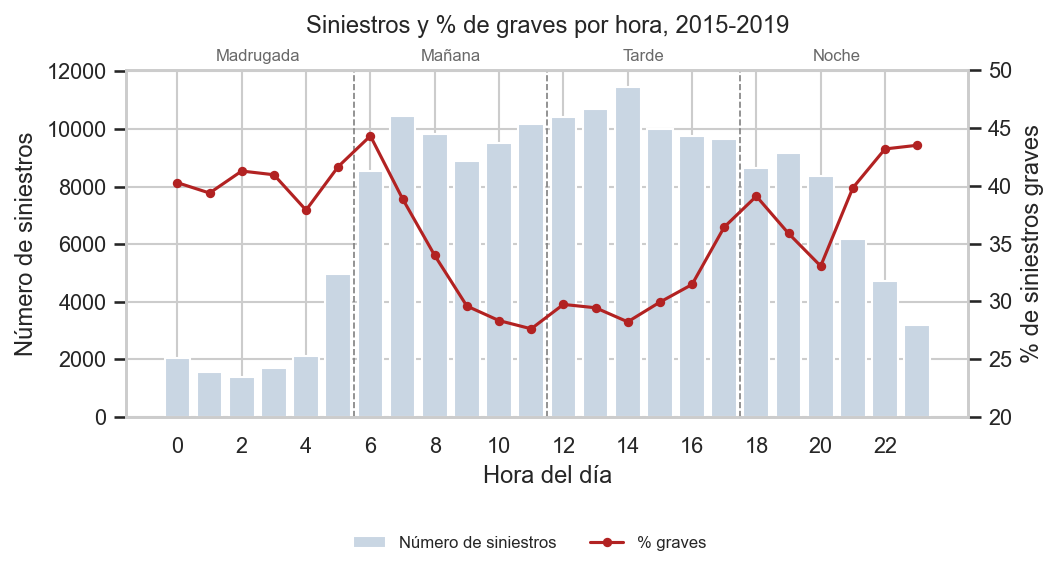

,siniestros,graves,pct_graves,pct_muertos
franja,,,,
Madrugada (0-6),13749,5569,40.505,3.455
Mañana (6-12),57391,19326,33.674,1.218
Tarde (12-18),61991,19066,30.756,1.079
Noche (18-24),40312,15342,38.058,1.942


In [21]:
h = base.groupby('hora').agg(siniestros=('grave', 'size'), pct=('grave', 'mean'))
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.set_axisbelow(True)
ax.bar(h.index, h.siniestros, color='#c9d6e3', label='Número de siniestros', zorder=2)
ax.set_xlabel('Hora del día'); ax.set_ylabel('Número de siniestros'); ax.set_xticks(range(0, 24, 2))
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(h.index, h.pct * 100, color='#b22222', marker='o', ms=3.5, label='% graves', zorder=3)
ax2.set_ylabel('% de siniestros graves'); ax2.set_ylim(20, 50)
for corte in [6, 12, 18]:
    ax.axvline(corte - 0.5, color='grey', ls='--', lw=0.8, zorder=1)
for x, t in zip([2.5, 8.5, 14.5, 20.5], ['Madrugada', 'Mañana', 'Tarde', 'Noche']):
    ax.text(x, 1.02, t, transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=8, color='dimgrey')
ax.set_title('Siniestros y % de graves por hora, 2015-2019', pad=18)
plt.tight_layout(); fig.subplots_adjust(bottom=0.25)
fig.legend(loc='lower center', ncol=2, fontsize=8, frameon=False)
plt.savefig('figs/fig1_hora.pdf'); plt.show()

franja_tab = base.groupby('franja', observed=True).agg(siniestros=('grave', 'size'), graves=('grave', 'sum'),
                                                       pct_graves=('grave', 'mean'), pct_muertos=('con_muertos', 'mean'))
franja_tab[['pct_graves', 'pct_muertos']] *= 100
display(franja_tab)

**Qué vemos.** Forma de "U": de día hay muchos siniestros pero menos graves (28–30 % entre las 9 y las 16); en la madrugada y al final de la noche hay menos siniestros pero cerca de 40 % o más son graves. El bloque "mañana" mezcla dos momentos distintos (6–9 y 9–12), por eso se probarán franjas de 3 horas.

#### 3.4 ¿Las localidades con más siniestros son las más graves?

C:\Users\dddan\AppData\Local\Temp\ipykernel_27140\2337651253.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  loc = base.groupby('localidad').agg(siniestros=('grave', 'size'), graves=('grave', 'sum'), pct_graves=('grave', 'mean'))


Spearman entre número de siniestros y % graves (19 localidades): -0.63


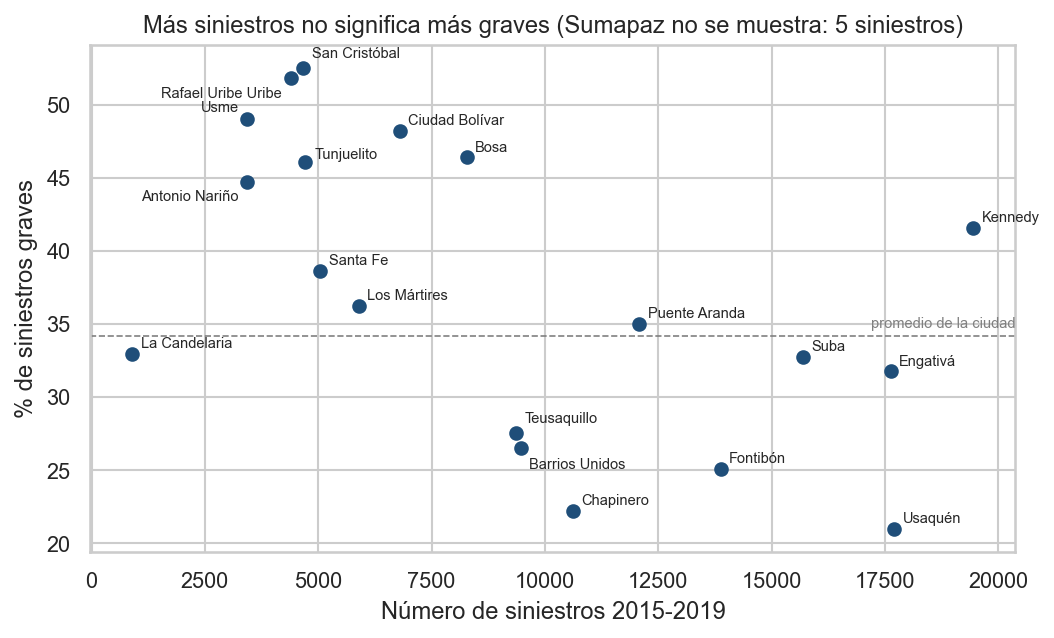

,siniestros,graves,pct_graves
localidad,,,
Sumapaz,5,3,60.000
San Cristóbal,4674,2455,52.525
Rafael Uribe Uribe,4389,2274,51.811
Usme,3429,1680,48.994
Ciudad Bolívar,6798,3277,48.205
Bosa,8274,3840,46.410
Tunjuelito,4701,2166,46.075
Antonio Nariño,3431,1535,44.739
Kennedy,19452,8087,41.574


In [22]:
loc = base.groupby('localidad').agg(siniestros=('grave', 'size'), graves=('grave', 'sum'), pct_graves=('grave', 'mean'))
loc['pct_graves'] *= 100
loc = loc.sort_values('pct_graves', ascending=False)
sin_sumapaz = loc.drop('Sumapaz')
rho = stats.spearmanr(sin_sumapaz.siniestros, sin_sumapaz.pct_graves).statistic
print(f'Spearman entre número de siniestros y % graves (19 localidades): {rho:.2f}')

desplaz = {'San Cristóbal': (4, 5, 'left'), 'Rafael Uribe Uribe': (-4, -9, 'right'), 'Antonio Nariño': (-4, -9, 'right'),
           'Tunjuelito': (5, 2, 'left'), 'Teusaquillo': (4, 5, 'left'), 'Barrios Unidos': (4, -10, 'left'), 'Usme': (-4, 4, 'right')}
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.scatter(sin_sumapaz.siniestros, sin_sumapaz.pct_graves, color='#1f4e79', zorder=3)
for nombre, fila in sin_sumapaz.iterrows():
    dx, dy, ha = desplaz.get(nombre, (4, 3, 'left'))
    ax.annotate(nombre, (fila.siniestros, fila.pct_graves), fontsize=7, xytext=(dx, dy), textcoords='offset points', ha=ha)
ax.axhline(base.grave.mean() * 100, color='grey', ls='--', lw=0.8)
ax.text(ax.get_xlim()[1], base.grave.mean() * 100 + 0.6, 'promedio de la ciudad', ha='right', fontsize=7, color='grey')
ax.set_xlabel('Número de siniestros 2015-2019'); ax.set_ylabel('% de siniestros graves')
ax.set_title('Más siniestros no significa más graves (Sumapaz no se muestra: 5 siniestros)')
plt.tight_layout(); plt.savefig('figs/fig2_localidades.pdf'); plt.show()
display(loc)

**Qué vemos.** Las localidades con más siniestros (Usaquén, Engativá, Suba) tienen menos proporción de graves, y las del sur (San Cristóbal, Rafael Uribe Uribe, Usme, Ciudad Bolívar) tienen cerca de la mitad o más. Kennedy es la excepción: muchos siniestros y proporción alta.

**Cuidado al leerlo.** Dos explicaciones posibles que los datos no separan: (1) allí los siniestros son más graves, o (2) allí se reportan menos los choques leves, lo que infla el porcentaje (supuesto S1). Por eso se hará la prueba "solo con muertos" y el resultado se presenta como "severidad en lo registrado".

#### 3.5 Las celdas localidad × franja

In [23]:
celdas = base.groupby(['localidad', 'franja'], observed=False).agg(n=('grave', 'size'), graves=('grave', 'sum')).reset_index()
assert len(celdas) == 80 and celdas.n.sum() == len(base), 'Se perdieron siniestros al agrupar'
celdas['prop'] = celdas.graves / celdas.n.replace(0, np.nan)
print('Mediana de siniestros por celda:', int(celdas.n.median()))
print('Celdas con menos de 30:', (celdas.n < 30).sum(), '| con menos de 100:', (celdas.n < 100).sum())
display(celdas[celdas.n < 100])

Mediana de siniestros por celda: 1517
Celdas con menos de 30: 4 | con menos de 100: 5


,localidad,franja,n,graves,prop
32,La Candelaria,Madrugada (0-6),51,24,0.471
60,Sumapaz,Madrugada (0-6),0,0,NaN
61,Sumapaz,Mañana (6-12),1,1,1.000
62,Sumapaz,Tarde (12-18),2,1,0.500
63,Sumapaz,Noche (18-24),2,1,0.500


**Qué vemos.** La mitad de las celdas tiene más de 1.500 siniestros. Las 4 de Sumapaz tienen menos de 30 (una tiene cero) y La Candelaria de madrugada 51. Ordenar por proporción cruda pondría arriba a una celda con 1 grave de 1 siniestro (100 %). Esto es lo que justifica apoyarse en el promedio de la ciudad en las celdas pequeñas.

#### 3.6 Día de la semana y tipo de lugar (solo descriptivo)

In [24]:
dia_tab = base.groupby('dia4').agg(siniestros=('grave', 'size'), graves=('grave', 'sum'), pct_graves=('grave', 'mean'))
lugar_tab = base.groupby('tipo_lugar').agg(siniestros=('grave', 'size'), graves=('grave', 'sum'), pct_graves=('grave', 'mean'))
dia_tab['pct_graves'] *= 100; lugar_tab['pct_graves'] *= 100
display(dia_tab.sort_values('pct_graves')); display(lugar_tab)

,siniestros,graves,pct_graves
dia4,,,
Viernes,27354,9018,32.968
Sábado,25988,8734,33.608
Lunes a jueves,98670,33565,34.017
Domingo o festivo,21431,7986,37.264


,siniestros,graves,pct_graves
tipo_lugar,,,
Intersección,32875,13414,40.803
Otros,6092,1234,20.256
Tramo de vía,134476,44655,33.207


**Qué vemos.** Domingos y festivos tienen algo más de graves; las intersecciones más que los tramos. Son diferencias menores que las de localidad y hora; quedan como descripción y como pruebas alternativas, como se fijó en el Avance 2.

#### 3.7 Matriz de asociación entre variables
Casi todas las variables son categorías, así que la correlación de Pearson no aplica. Usamos:
- **V de Cramér** (0 a 1) entre variables de cada siniestro: qué tan fuerte es la relación entre dos variables de categorías.
- **Spearman** entre variables resumidas por celda: relación de orden, sin suponer una línea recta.

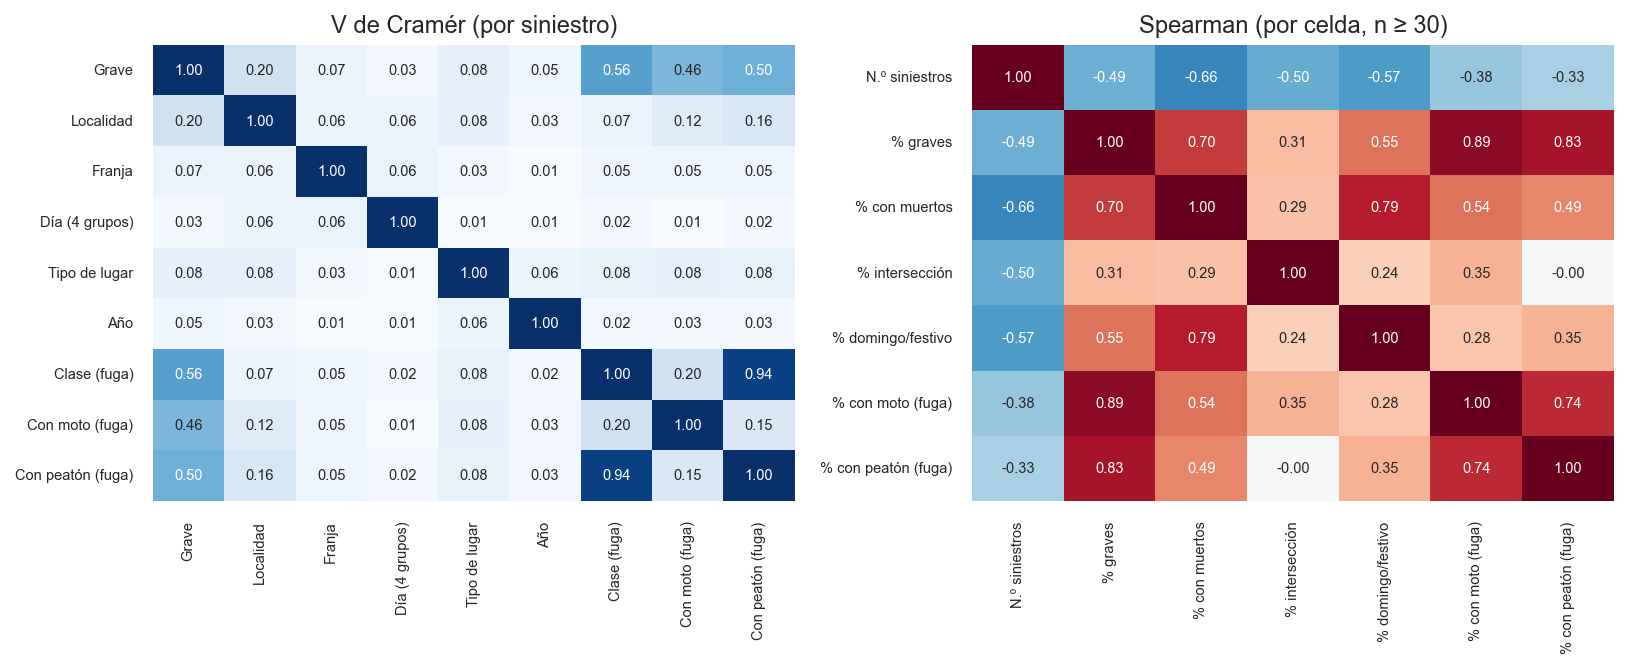

V de Cramér con Grave: {'Localidad': 0.2, 'Franja': 0.07, 'Día (4 grupos)': 0.03, 'Tipo de lugar': 0.08, 'Año': 0.05, 'Clase (fuga)': 0.56, 'Con moto (fuga)': 0.46, 'Con peatón (fuga)': 0.5}


In [25]:
def v_cramer(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum(); r, k = tabla.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

vars_cat = {'Grave': base.grave, 'Localidad': base.localidad, 'Franja': base.franja.astype(str), 'Día (4 grupos)': base.dia4,
            'Tipo de lugar': base.tipo_lugar, 'Año': base.anio, 'Clase (fuga)': base.clase,
            'Con moto (fuga)': base.con_moto, 'Con peatón (fuga)': base.con_peaton}
nombres_v = list(vars_cat)
V = pd.DataFrame(np.eye(len(nombres_v)), index=nombres_v, columns=nombres_v)
for i, a in enumerate(nombres_v):
    for b in nombres_v[i + 1:]:
        V.loc[a, b] = V.loc[b, a] = v_cramer(vars_cat[a], vars_cat[b])

aux = base.assign(es_interseccion=(base.tipo_lugar == 'Intersección').astype(int),
                  es_domingo=(base.dia4 == 'Domingo o festivo').astype(int))
pc = aux.groupby(['localidad', 'franja'], observed=True).agg(
    **{'N.º siniestros': ('grave', 'size'), '% graves': ('grave', 'mean'), '% con muertos': ('con_muertos', 'mean'),
       '% intersección': ('es_interseccion', 'mean'), '% domingo/festivo': ('es_domingo', 'mean'),
       '% con moto (fuga)': ('con_moto', 'mean'), '% con peatón (fuga)': ('con_peaton', 'mean')})
S = pc[pc['N.º siniestros'] >= 30].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
sns.heatmap(V, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=axes[0], cbar=False, annot_kws={'size': 7})
axes[0].set_title('V de Cramér (por siniestro)')
sns.heatmap(S, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[1], cbar=False, annot_kws={'size': 7})
axes[1].set_title('Spearman (por celda, n ≥ 30)')
for a in axes: a.tick_params(labelsize=7)
plt.tight_layout(); plt.savefig('figs/fig4_correlaciones.pdf'); plt.show()
print('V de Cramér con Grave:', V['Grave'].drop('Grave').round(2).to_dict())

**Qué vemos.** Lo que más se asocia con la gravedad son las variables de fuga (clase del siniestro, moto, peatón): confirma por qué no pueden entrar al modelo. Entre las que sí se conocen antes, la localidad es la que más se asocia (alrededor de 0,20); franja, tipo de lugar y día mucho menos. Es normal: el modelo no busca adivinar si *un* siniestro será grave, sino estimar la proporción de graves de cada zona y hora.

#### 3.8 ¿Ordenar por número de graves y por proporción de graves da lo mismo?
La comparación central del proyecto: el criterio actual (cuántos graves se acumulan) frente al propuesto (qué parte es grave).

In [26]:
c = celdas[celdas.n >= 30].copy()
c['puesto_conteo'] = c.graves.rank(ascending=False, method='min').astype(int)
c['puesto_proporcion'] = c.prop.rank(ascending=False, method='min').astype(int)
top_prop = c.nsmallest(10, 'puesto_proporcion')
print('Celdas del top 10 por proporción que están en el top 10 por conteo:', (top_prop.puesto_conteo <= 10).sum())
print('Mejor puesto por conteo dentro del top 10 por proporción:', top_prop.puesto_conteo.min())
print('De esas 10, cuántas son de noche:', top_prop.franja.astype(str).str.startswith('Noche').sum())
display(top_prop[['localidad', 'franja', 'n', 'graves', 'prop', 'puesto_conteo']])

Celdas del top 10 por proporción que están en el top 10 por conteo: 0
Mejor puesto por conteo dentro del top 10 por proporción: 19
De esas 10, cuántas son de noche: 6


,localidad,franja,n,graves,prop,puesto_conteo
49,San Cristóbal,Mañana (6-12),1537,845,0.550,27
47,Rafael Uribe Uribe,Noche (18-24),1146,623,0.544,43
51,San Cristóbal,Noche (18-24),1235,665,0.538,40
79,Usme,Noche (18-24),898,480,0.535,55
45,Rafael Uribe Uribe,Mañana (6-12),1331,695,0.522,38
46,Rafael Uribe Uribe,Tarde (12-18),1497,754,0.504,34
50,San Cristóbal,Tarde (12-18),1539,775,0.504,33
3,Antonio Nariño,Noche (18-24),859,432,0.503,57
19,Ciudad Bolívar,Noche (18-24),1717,859,0.500,25
11,Bosa,Noche (18-24),2167,1074,0.496,19


**Qué vemos.** Ninguna de las 10 celdas con mayor proporción de graves está entre las 10 con más siniestros graves; la mejor ubicada por conteo es Bosa de noche, en el puesto 19. Las 10 son de localidades del sur y 6 de ellas son de noche. Si la Secretaría ordena solo por conteo, estas zonas y horas no aparecen arriba. Cuáles de estas diferencias son seguras y cuáles azar es lo que responde el modelo.

#### 3.9 Tablas para el documento

In [27]:
def tabla_latex(df, columnas, encabezados, caption, label, ruta, primera='{}'):
    filas = ['\\begin{table}[h]\\centering\\small', f'\\caption{{{caption}}}\\label{{{label}}}',
             '\\begin{tabular}{l' + 'r' * len(columnas) + '}', '\\toprule', ' & '.join(encabezados) + ' \\\\', '\\midrule']
    for idx, f in df.iterrows():
        valores = [f'{f[col]:,.0f}'.replace(',', '.') if 'pct' not in col else f'{f[col]:.1f}'.replace('.', ',') for col in columnas]
        filas.append(f'{idx} & ' + ' & '.join(valores) + ' \\\\')
    filas += ['\\bottomrule', '\\end{tabular}', '\\end{table}']
    open(ruta, 'w', encoding='utf-8').write('\n'.join(filas))

enc = ['Siniestros', 'Graves', '\\% graves']
tabla_latex(franja_tab, ['siniestros', 'graves', 'pct_graves'], ['Franja'] + enc, 'Siniestros y proporción de graves por franja horaria, 2015--2019.', 'tab:franja', 'tablas/tab_franja.tex')
tabla_latex(loc, ['siniestros', 'graves', 'pct_graves'], ['Localidad'] + enc, 'Siniestros y proporción de graves por localidad, 2015--2019.', 'tab:localidad', 'tablas/tab_localidad.tex')
tabla_latex(por_anio, ['siniestros', 'graves', 'pct_graves'], ['Año'] + enc, 'Siniestros y proporción de graves por año.', 'tab:anio', 'tablas/tab_anio.tex')
tabla_latex(dia_tab, ['siniestros', 'graves', 'pct_graves'], ['Día'] + enc, 'Siniestros y proporción de graves por día, 2015--2019.', 'tab:dia', 'tablas/tab_dia.tex')
tabla_latex(lugar_tab, ['siniestros', 'graves', 'pct_graves'], ['Tipo de lugar'] + enc, 'Siniestros y proporción de graves por tipo de lugar, 2015--2019.', 'tab:lugar', 'tablas/tab_lugar.tex')
print(sorted(os.listdir('tablas')))

['tab_anio.tex', 'tab_dia.tex', 'tab_franja.tex', 'tab_localidad.tex', 'tab_lugar.tex']


### Figuras exploratorias del informe final (Figuras 1 a 4)
Mismo código que la sección 2 de `Grupo2_EntregaFinal_Bayesiana.py`.

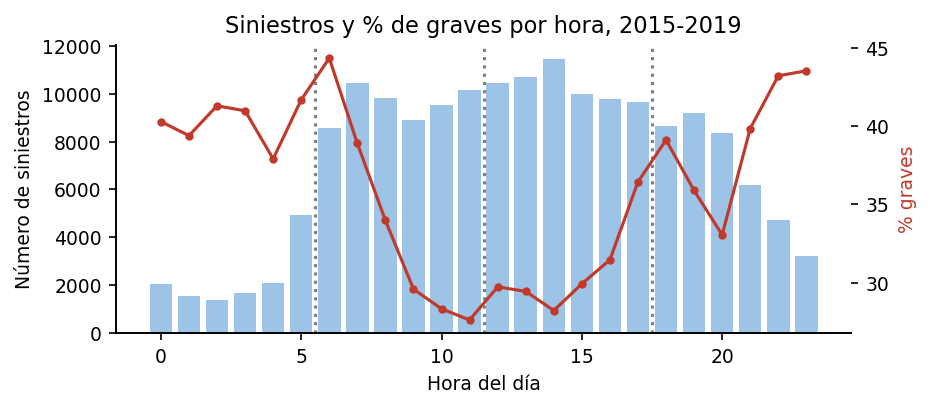

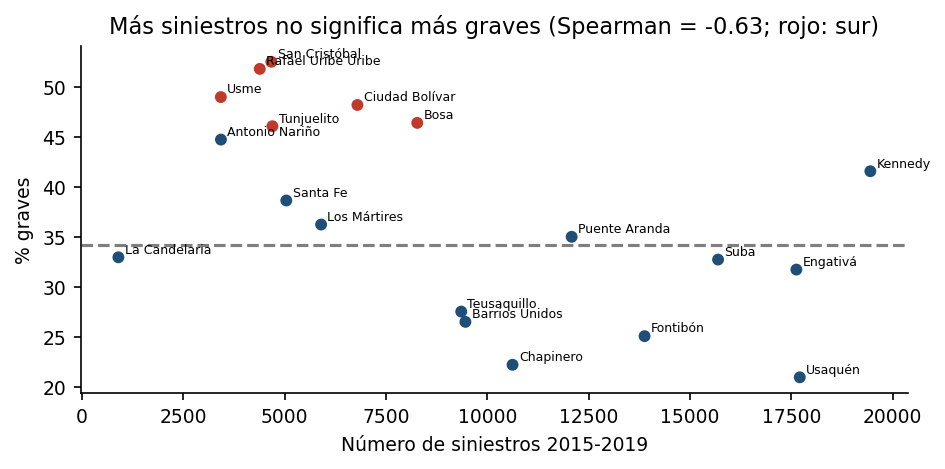

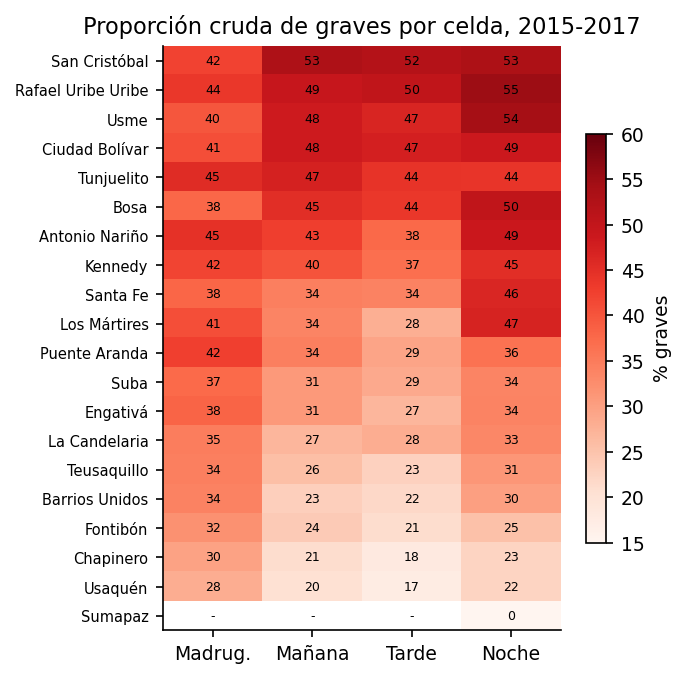

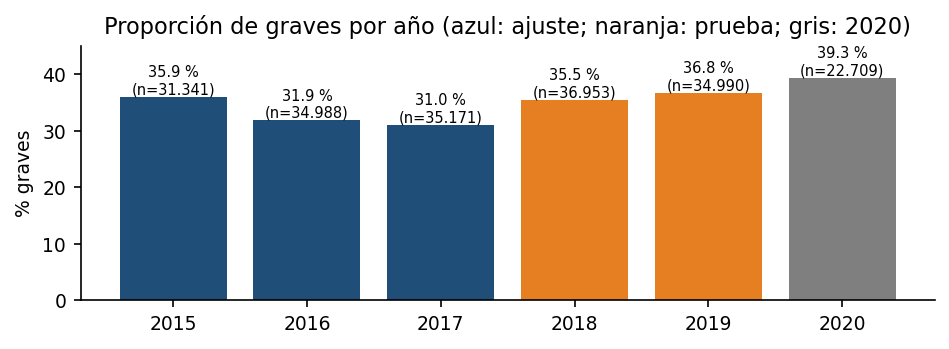

Guardado: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks\salidas\resultados\02_eda.json


In [28]:
os.chdir(BASE)
# se quita el estilo de seaborn del EDA original para que las figuras sean idénticas a las del informe
plt.rcdefaults()
plt.rcParams.update({'figure.dpi': 150, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
R = {}
# ---------------------------------------------------------------------------
# 2. Figuras exploratorias (EDA)
# ---------------------------------------------------------------------------
base = df[df.anio <= 2019]
h = base.groupby("hora").grave.agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.bar(h.index, h["size"], color="#9dc3e6")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Número de siniestros")
for x in (6, 12, 18):
    ax.axvline(x - 0.5, ls=":", color=GRIS)
ax2 = ax.twinx()
ax2.plot(h.index, 100 * h["mean"], color=ROJO, marker="o", ms=3)
ax2.set_ylabel("% graves", color=ROJO)
ax.set_title("Siniestros y % de graves por hora, 2015-2019")
fig.tight_layout()
fig.savefig(FIG / "eda_hora.png")
plt.show()

lo = base.groupby("localidad").grave.agg(["size", "mean"]).drop("Sumapaz")
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.scatter(lo["size"], 100 * lo["mean"], c=[ROJO if i in SUR else AZUL for i in lo.index], s=22)
for nom, r in lo.iterrows():
    ax.annotate(nom, (r["size"], 100 * r["mean"]), fontsize=6, xytext=(3, 2), textcoords="offset points")
ax.axhline(100 * base.grave.mean(), ls="--", color=GRIS)
ax.set_xlabel("Número de siniestros 2015-2019")
ax.set_ylabel("% graves")
rho_loc = st.spearmanr(lo["size"], lo["mean"])[0]
ax.set_title(f"Más siniestros no significa más graves (Spearman = {rho_loc:.2f}; rojo: sur)")
fig.tight_layout()
fig.savefig(FIG / "eda_localidad.png")
plt.show()
R["eda_rho_localidad"] = float(rho_loc)

mat = (c_tr.y / c_tr.n.replace(0, np.nan)).values.reshape(L, F)
orden_loc = np.argsort(-np.nanmean(mat, axis=1))
fig, ax = plt.subplots(figsize=(4.6, 4.6))
im = ax.imshow(100 * mat[orden_loc], cmap="Reds", aspect="auto", vmin=15, vmax=60)
ax.set_xticks(range(F), ["Madrug.", "Mañana", "Tarde", "Noche"])
ax.set_yticks(range(L), [LOCS[i] for i in orden_loc], fontsize=7)
for i, li in enumerate(orden_loc):
    for j in range(F):
        v = mat[li, j]
        ax.text(j, i, "-" if np.isnan(v) else f"{100 * v:.0f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, label="% graves", shrink=0.7)
ax.set_title("Proporción cruda de graves por celda, 2015-2017")
fig.tight_layout()
fig.savefig(FIG / "eda_celdas.png")
plt.show()

an = df.groupby("anio").grave.agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(6.4, 2.4))
cols = [AZUL] * 3 + [NARANJA] * 2 + [GRIS]
ax.bar(an.index, 100 * an["mean"], color=cols)
for x, v, n in zip(an.index, an["mean"], an["size"]):
    ax.text(x, 100 * v + 0.5, f"{100 * v:.1f} %\n(n={n:,})".replace(",", "."), ha="center", fontsize=7)
ax.set_ylim(0, 45)
ax.set_ylabel("% graves")
ax.set_title("Proporción de graves por año (azul: ajuste; naranja: prueba; gris: 2020)")
fig.tight_layout()
fig.savefig(FIG / "eda_anio.png")
plt.show()
R["eda_anio"] = {int(k): float(v) for k, v in an["mean"].items()}
guardar_json(R, '02_eda.json')

## 3. Del EDA al modelo: forma por celda, priors de la Primera Entrega y partición
**Qué hace.** Secciones 4, 5 y 6 del notebook EDA original, solo con 2015–2017: forma de la proporción por celda, heterogeneidad (χ²), estructura localidad + franja, chequeo predictivo a priori de la Primera Entrega y referencias de comparación (ciudad, proporción cruda). Al final, el conteo de celdas del informe final (80 / 77 con datos / 75 evaluables / 21 pequeñas).

**Entradas.** `datos/siniestros_limpios.csv`.  
**Salidas.** `datos/celdas_ajuste_2015_2017.csv`, `celdas_prueba_2018_2019.csv`, `celdas_por_anio_2015_2019.csv`; `salidas/eda_original/figs/fig3, fig5`; `salidas/resultados/03_celdas.json`.

In [29]:
# Tema de seaborn del EDA original
sns.set_theme(style='whitegrid', font_scale=0.95)

In [30]:
# Se recargan los datos limpios: la sección 2 reutilizó el nombre `base` para sus figuras
# Datos limpios producidos por 01 (no se vuelve a leer el Excel)
from comun import *   # restaura los nombres comunes
sin = pd.read_csv(ruta_datos('siniestros_limpios.csv'), parse_dates=['fecha'])
# como en el notebook original: categorías completas (20 localidades x 4 franjas = 80 celdas, con Sumapaz vacías)
sin['localidad'] = pd.Categorical(sin.localidad, categories=LOCS)
sin['franja'] = pd.Categorical(sin.franja, categories=FRANJAS, ordered=True)
sin['franja3h'] = pd.Categorical(sin.franja3h, categories=FR3, ordered=True)
base =sin[sin.anio <= 2019].copy()
ajuste_df = base[base.periodo == 'Ajuste 2015-2017']
CARPETA_TRABAJADOS = str(DATOS)
(SALIDAS / 'eda_original' / 'figs').mkdir(parents=True, exist_ok=True)
(SALIDAS / 'eda_original' / 'tablas').mkdir(parents=True, exist_ok=True)
os.chdir(SALIDAS / 'eda_original')     # las figuras y tablas del EDA original quedan aquí
print(len(sin), 'siniestros;', len(base), 'en 2015-2019;', len(ajuste_df), 'en 2015-2017')

196152 siniestros; 173443 en 2015-2019; 101500 en 2015-2017


### 4. Del análisis exploratorio al modelo (solo 2015–2017)
Aquí se toman decisiones del modelo, así que se usa **solo el periodo de ajuste**.

#### 4.1 Forma de la distribución por celda

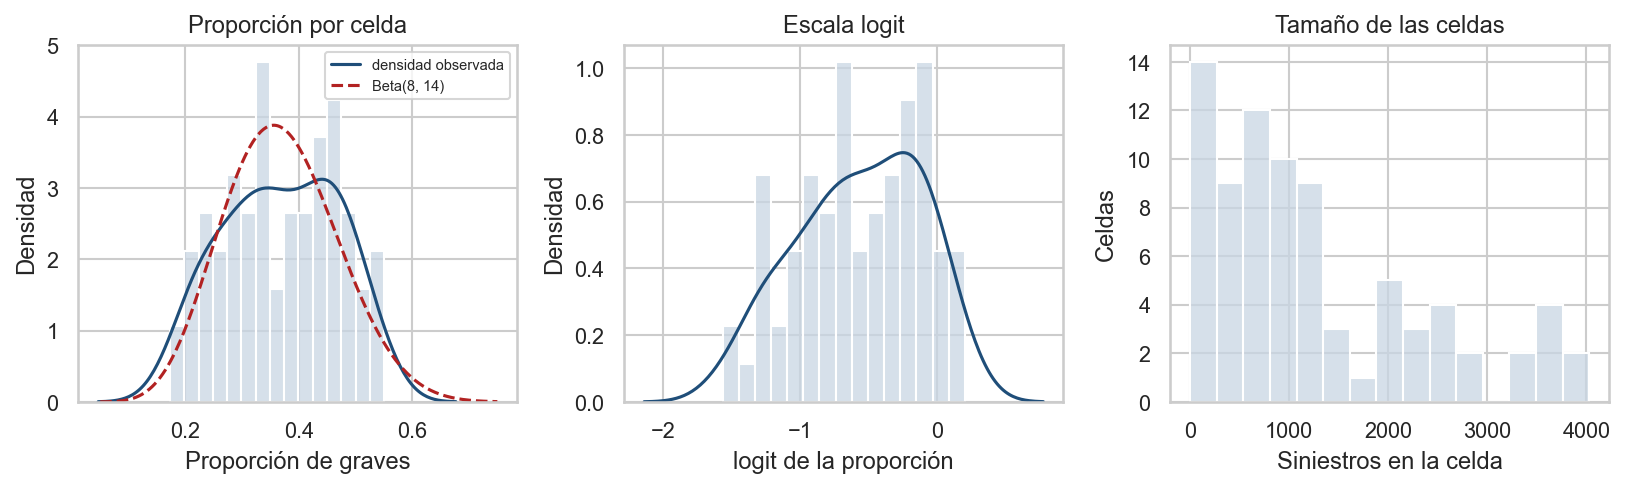

Celdas con n>=30: 75 | media 0.369 | desviación entre celdas 0.100 | rango 0.173-0.550
Beta por momentos: Beta(8.2, 14.0), concentración cercana a 22


In [31]:
cel_aj = ajuste_df.groupby(['localidad', 'franja'], observed=False).agg(n=('grave', 'size'), graves=('grave', 'sum')).reset_index()
c30 = cel_aj[cel_aj.n >= 30].copy()
c30['prop'] = c30.graves / c30.n
c30['logit'] = np.log(c30.prop / (1 - c30.prop))
media, var = c30.prop.mean(), c30.prop.var()
k_mom = media * (1 - media) / var - 1
a_mom, b_mom = media * k_mom, (1 - media) * k_mom

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
sns.histplot(c30.prop, bins=15, stat='density', color='#c9d6e3', ax=axes[0])
sns.kdeplot(c30.prop, color='#1f4e79', ax=axes[0], clip=(0, 1), label='densidad observada')
x = np.linspace(0.05, 0.75, 300)
axes[0].plot(x, stats.beta(a_mom, b_mom).pdf(x), color='#b22222', ls='--', label=f'Beta({a_mom:.0f}, {b_mom:.0f})')
axes[0].set_xlabel('Proporción de graves'); axes[0].set_ylabel('Densidad'); axes[0].legend(fontsize=7); axes[0].set_title('Proporción por celda')
sns.histplot(c30.logit, bins=15, stat='density', color='#c9d6e3', ax=axes[1])
sns.kdeplot(c30.logit, color='#1f4e79', ax=axes[1])
axes[1].set_xlabel('logit de la proporción'); axes[1].set_ylabel('Densidad'); axes[1].set_title('Escala logit')
sns.histplot(cel_aj.n, bins=15, color='#c9d6e3', ax=axes[2])
axes[2].set_xlabel('Siniestros en la celda'); axes[2].set_ylabel('Celdas'); axes[2].set_title('Tamaño de las celdas')
plt.tight_layout(); plt.savefig('figs/fig3_histogramas.pdf'); plt.show()
print(f'Celdas con n>=30: {len(c30)} | media {media:.3f} | desviación entre celdas {np.sqrt(var):.3f} | rango {c30.prop.min():.3f}-{c30.prop.max():.3f}')
print(f'Beta por momentos: Beta({a_mom:.1f}, {b_mom:.1f}), concentración cercana a {k_mom:.0f}')

**Qué vemos y qué decidimos.**
- La proporción por celda va de 17 % a 55 %. La Beta con la misma media y dispersión es una **aproximación razonable**, pero no perfecta: la densidad observada es más plana que la Beta entre 0,3 y 0,45 y tiene un pico hacia 0,47 que la Beta no captura. Esa forma es una pista de que hay grupos de celdas (por ejemplo, sur y noche); ver 4.3.
- En escala logit la distribución es más simétrica; esa es la escala del modelo M2 (logística jerárquica).
- Dentro de cada celda, el número de graves entre *n* siniestros es un conteo de sí/no: **Binomial**.

#### 4.2 ¿Las celdas son distintas de verdad?

In [32]:
p_aj = c30.graves.sum() / c30.n.sum()
chi2 = (((c30.graves - c30.n * p_aj) ** 2) / (c30.n * p_aj * (1 - p_aj))).sum()
gl = len(c30) - 1
print(f'Chi-cuadrado = {chi2:,.0f} con {gl} grados de libertad (si fuera azar, estaría cerca de {gl})')

Chi-cuadrado = 4,648 con 74 grados de libertad (si fuera azar, estaría cerca de 74)


**Qué vemos.** El valor es unas 60 veces lo esperado por azar: las celdas son distintas. Esto descarta una sola probabilidad para toda la ciudad. **Ojo:** esta prueba dice que las celdas difieren, no que sean intercambiables; eso se revisa a continuación.

#### 4.3 ¿Las diferencias tienen estructura?
Si las celdas fueran intercambiables, saber la localidad o la franja no diría nada sobre su severidad. Lo comprobamos ajustando una regresión logística con efectos aditivos de localidad y franja (sin interacción) y midiendo qué parte de la diferencia entre celdas explica (devianza explicada).

In [33]:
cc = cel_aj[cel_aj.n > 0].copy()
X = pd.get_dummies(cc[['localidad', 'franja']].astype(str), drop_first=True).astype(float)
X.insert(0, 'intercepto', 1.0); Xv = X.values
y, n = cc.graves.values, cc.n.values
beta = np.zeros(Xv.shape[1])
for _ in range(50):                          # mínimos cuadrados reponderados (cómo se ajusta una logística)
    eta = Xv @ beta; mu = 1 / (1 + np.exp(-eta)); W = n * mu * (1 - mu)
    z = eta + (y - n * mu) / np.clip(W, 1e-9, None)
    beta = np.linalg.solve(Xv.T @ (Xv * W[:, None]), Xv.T @ (W * z))
mu = 1 / (1 + np.exp(-Xv @ beta))

def devianza(y, n, mu):
    t1 = np.where(y > 0, y * np.log(np.where(y > 0, y / (n * mu), 1)), 0)
    t2 = np.where(n - y > 0, (n - y) * np.log(np.where(n - y > 0, (n - y) / (n * (1 - mu)), 1)), 0)
    return 2 * (t1 + t2).sum()

D_nula = devianza(y, n, np.full(len(cc), y.sum() / n.sum()))
D_aditiva = devianza(y, n, mu)
print(f'Devianza explicada por localidad + franja: {1 - D_aditiva / D_nula:.1%}')
print(f'Devianza que queda: {D_aditiva:,.0f} con {len(cc) - Xv.shape[1]} grados de libertad')

Devianza explicada por localidad + franja: 94.9%
Devianza que queda: 240 con 54 grados de libertad


**Qué vemos y qué decidimos.** Localidad y franja juntas, sin interacción, explican cerca del 95 % de la diferencia entre celdas. Es decir, las celdas **no** son intercambiables: hay estructura (una localidad del sur tiende a ser severa en todas sus franjas, y la noche es severa en casi todas las localidades). Lo que sobra es poco, pero más de lo que daría el azar, así que puede haber algo de interacción.

Por eso:
- **M1 (Beta-Binomial jerárquico)** queda como **modelo de partida**: es el más simple, se puede programar a mano con Gibbs y Metropolis–Hastings, y sirve de referencia.
- **M2 (logística jerárquica con localidad, franja, interacción y año)** es la respuesta a esta estructura y el candidato principal para el resultado final.

### 5. Priors y chequeo predictivo a priori

| Pieza | Prior | En palabras |
|---|---|---|
| m | Beta(2, 4) | Severidad típica de la ciudad. Centrada en 33 %, acepta de 5 % a 72 %. Prior débil, informada por la literatura: Vergel-Tovar et al. (2020, tabla 1) reportan cerca de 30 % de siniestros con víctimas en vías arteriales de Bogotá, 2012–2016. **Ojo:** ese periodo se solapa con 2015–2016 de nuestra base, así que no es información totalmente independiente; por eso la prior se deja ancha. |
| κ | Gamma(2; 0,04) | Cuánto se parecen las celdas al promedio, leído como "cuántos siniestros presta la ciudad a cada celda". Media 50, rango de 6 a 140. |

#### 5.1 Chequeo predictivo a priori
Se simulan ciudades usando solo las priors y **los tamaños reales de las celdas de 2015–2017**: se sortean m y κ, la severidad de cada celda y el número de graves con su *n* real. Luego se comparan con lo observado cuatro cosas que se pueden medir: la media, la diferencia típica entre celdas, el rango y el % de celdas por encima de 50 %. Si lo observado cae dentro de lo que simulan las priors, las priors no lo descartan.

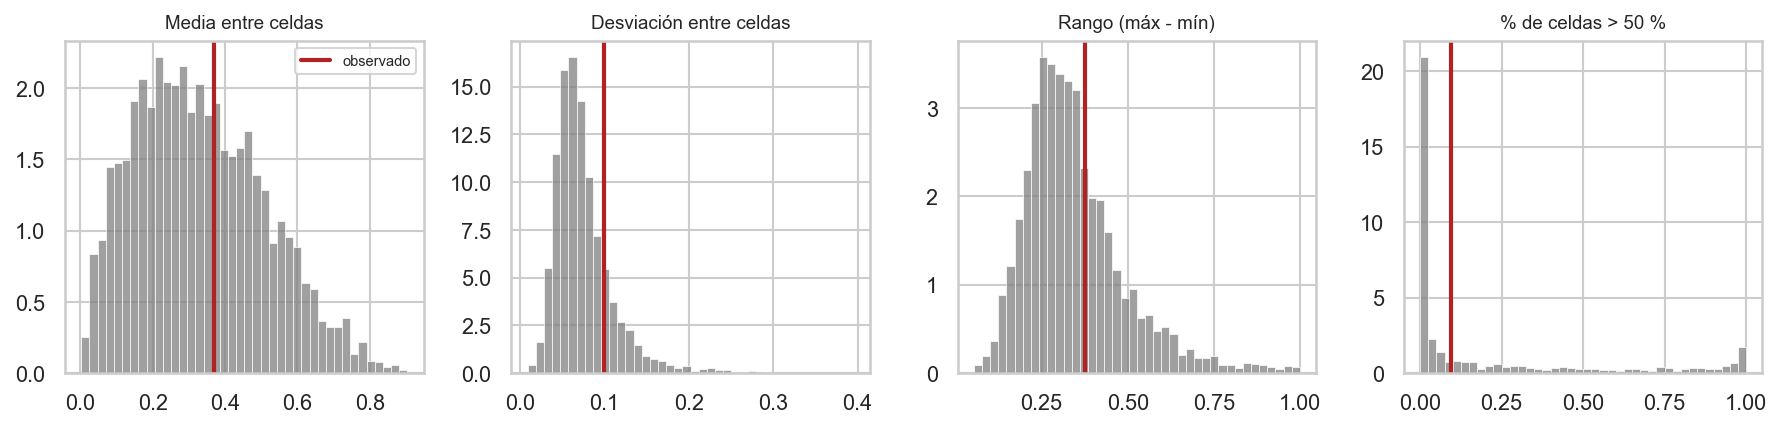

,observado,percentil en lo simulado,simulado 5 %,simulado 95 %
medida,,,,
Media entre celdas,0.369,0.607,0.074,0.650
Desviación entre celdas,0.099,0.826,0.034,0.140
Rango (máx - mín),0.377,0.674,0.159,0.631
% de celdas > 50 %,0.093,0.625,0.000,0.973


In [34]:
S_SIM = 4000
n_aj = cel_aj.n.values
m_sim = rng.beta(2, 4, S_SIM)
k_sim = rng.gamma(2, 1 / 0.04, S_SIM)
theta_sim = rng.beta(m_sim[:, None] * k_sim[:, None], (1 - m_sim[:, None]) * k_sim[:, None], size=(S_SIM, len(n_aj)))
y_sim = rng.binomial(n_aj, theta_sim)
mask = n_aj >= 30
p_sim = y_sim[:, mask] / n_aj[mask]
p_obs = (cel_aj.graves / cel_aj.n.replace(0, np.nan)).values[mask]

medidas = {'Media entre celdas': lambda a: a.mean(axis=-1), 'Desviación entre celdas': lambda a: a.std(axis=-1),
           'Rango (máx - mín)': lambda a: a.max(axis=-1) - a.min(axis=-1), '% de celdas > 50 %': lambda a: (a > 0.5).mean(axis=-1)}
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
filas = []
for ax, (nombre, f) in zip(axes, medidas.items()):
    sim, obs = f(p_sim), f(p_obs)
    sns.histplot(sim, ax=ax, color='grey', stat='density', bins=40)
    ax.axvline(obs, color='#b22222', lw=2, label='observado')
    ax.set_title(nombre, fontsize=9); ax.set_ylabel('')
    filas.append({'medida': nombre, 'observado': obs, 'percentil en lo simulado': np.mean(sim < obs),
                  'simulado 5 %': np.quantile(sim, 0.05), 'simulado 95 %': np.quantile(sim, 0.95)})
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig('figs/fig5_priors.pdf'); plt.show()
display(pd.DataFrame(filas).set_index('medida'))

**Qué vemos.** Las cuatro medidas observadas caen dentro del 90 % central de lo que simulan las priors (percentiles entre 0,6 y 0,85). Las priors permiten ciudades muy distintas pero no descartan la nuestra: es lo que se busca de una prior débil.

### 6. Preparación del entrenamiento y referencias de comparación
Se guardan los conteos por celda (y por celda y año, para el efecto de año de M2). Las referencias que el modelo debe superar en 2018–2019, todas fijadas en el Avance 2:
- **Agrupamiento completo:** una sola probabilidad para la ciudad.
- **Sin agrupamiento:** la proporción cruda de cada celda en 2015–2017.
- **Criterio actual:** ordenar por número de siniestros graves en 2015–2017.

Medidas: Brier y log-loss (más bajo es mejor), Spearman entre el orden de 2015–2017 y la proporción observada en 2018–2019 (criterio c del A2) y coincidencias en el top 10.

In [35]:
def a_celdas(df, por=('localidad', 'franja')):
    return df.groupby(list(por), observed=False).agg(n=('grave', 'size'), graves=('grave', 'sum')).reset_index()

ajuste = a_celdas(base[base.periodo == 'Ajuste 2015-2017'])
prueba = a_celdas(base[base.periodo == 'Prueba 2018-2019'])
por_anio_celda = a_celdas(base, ('localidad', 'franja', 'anio'))
assert ajuste.n.sum() + prueba.n.sum() == len(base)
ajuste.to_csv(os.path.join(CARPETA_TRABAJADOS, 'celdas_ajuste_2015_2017.csv'), index=False)
prueba.to_csv(os.path.join(CARPETA_TRABAJADOS, 'celdas_prueba_2018_2019.csv'), index=False)
por_anio_celda.to_csv(os.path.join(CARPETA_TRABAJADOS, 'celdas_por_anio_2015_2019.csv'), index=False)

p_ciudad = ajuste.graves.sum() / ajuste.n.sum()
prop_cruda = (ajuste.graves / ajuste.n.replace(0, np.nan)).fillna(p_ciudad).clip(1e-3, 1 - 1e-3)

def brier(p, cp):
    y, n = cp.graves, cp.n
    return ((y * (1 - p) ** 2 + (n - y) * p ** 2).sum()) / n.sum()

def logloss(p, cp):
    y, n = cp.graves, cp.n
    return -((y * np.log(p) + (n - y) * np.log(1 - p)).sum()) / n.sum()

ok = (ajuste.n >= 30) & (prueba.n >= 30)
p_prueba = prueba.graves / prueba.n
top_real = set(p_prueba[ok].nlargest(10).index)
ref = pd.DataFrame({
    'Brier': [brier(p_ciudad, prueba), brier(prop_cruda.values, prueba), np.nan],
    'Log-loss': [logloss(p_ciudad, prueba), logloss(prop_cruda.values, prueba), np.nan],
    'Spearman con 2018-2019': [np.nan, stats.spearmanr(prop_cruda[ok], p_prueba[ok]).statistic,
                               stats.spearmanr(ajuste.graves[ok], p_prueba[ok]).statistic],
    'Coincidencias top 10': [np.nan, len(set(prop_cruda[ok].nlargest(10).index) & top_real),
                             len(set(ajuste.graves[ok].nlargest(10).index) & top_real)]},
    index=['Agrupamiento completo (ciudad)', 'Sin agrupamiento (proporción cruda)', 'Criterio actual (conteo de graves)'])
print(f'Severidad media en ajuste: {p_ciudad:.3f} | en prueba: {prueba.graves.sum() / prueba.n.sum():.3f}')
display(ref.round(4))

Severidad media en ajuste: 0.328 | en prueba: 0.361


,Brier,Log-loss,Spearman con 2018-2019,Coincidencias top 10
Agrupamiento completo (ciudad),0.232,0.656,NaN,NaN
Sin agrupamiento (proporción cruda),0.222,0.635,0.921,6.000
Criterio actual (conteo de graves),NaN,NaN,-0.329,0.000


**Qué vemos.** El orden por conteo de graves va **en contra** de la severidad de 2018–2019 (Spearman negativo, ninguna coincidencia en el top 10): señala las zonas con más tráfico, no las más severas. La proporción cruda ordena bien las celdas grandes (Spearman cercano a 0,9) pero falla en las pequeñas. El modelo jerárquico tiene que ordenar al menos tan bien como la proporción cruda y predecir mejor (Brier y log-loss más bajos).

### Celdas del informe final

In [36]:
os.chdir(BASE)
R = dict(celdas=L * F, con_datos=int((n_tr > 0).sum()), evaluables=int(eleg.sum()),
         pequenas_menos_500=int((n_tr < 500).sum()), n_ajuste=int(n_tr.sum()), graves_ajuste=int(y_tr.sum()),
         n_prueba=int(n_te.sum()), graves_prueba=int(y_te.sum()),
         p_ajuste=y_tr.sum() / n_tr.sum(), p_prueba=y_te.sum() / n_te.sum(), p_2020=d20.grave.mean())
print(limpio(R))
guardar_json(R, '03_celdas.json')

{'celdas': 80, 'con_datos': 77, 'evaluables': 75, 'pequenas_menos_500': 21, 'n_ajuste': 101500, 'graves_ajuste': 33331, 'n_prueba': 71943, 'graves_prueba': 25972, 'p_ajuste': 0.32838, 'p_prueba': 0.36101, 'p_2020': 0.39324}
Guardado: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks\salidas\resultados\03_celdas.json


## 4. Priors de M1 y M2 y chequeo predictivo a priori
**Qué hace.** Simula 4.000 ciudades solo con las priors de M1 y M2 y los tamaños reales de las celdas de 2015–2017, y compara cuatro estadísticos con lo observado (Figura 5 del informe).

**Entradas.** `datos/siniestros_limpios.csv`.  
**Salidas.** `salidas/figuras/prior_predictivo.png`; `salidas/resultados/04_priors.json`.

In [37]:
# Estilo de figuras del informe (se quita el tema de seaborn que usa el EDA original)
os.chdir(BASE)
plt.rcdefaults()
plt.rcParams.update({'figure.dpi': 150, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})

### Priors (Tabla 1 del informe)
| Parámetro | Prior | Argumento |
|---|---|---|
| $m$ | Beta(2, 4) | Media 1/3; débilmente informada por Vergel-Tovar et al. (2020), ≈30 % con víctimas |
| $\kappa$ | Gamma(2; 0,04) | Media 50: cuántos siniestros "presta" la ciudad a cada celda |
| $\mu$ | N(logit 1/3, 1) | Mismo centro que $m$ en escala logit |
| $\sigma_a^2, \sigma_b^2$ | IG(3; 0,5) | Media 0,25: localidad o franja típica a ±11 puntos del centro |
| $\sigma_g^2$ | IG(3; 0,1) | Interacción menor que los efectos principales |
| $\sigma_d^2$ | IG(3; 0,05) | El nivel anual varía pocos puntos |

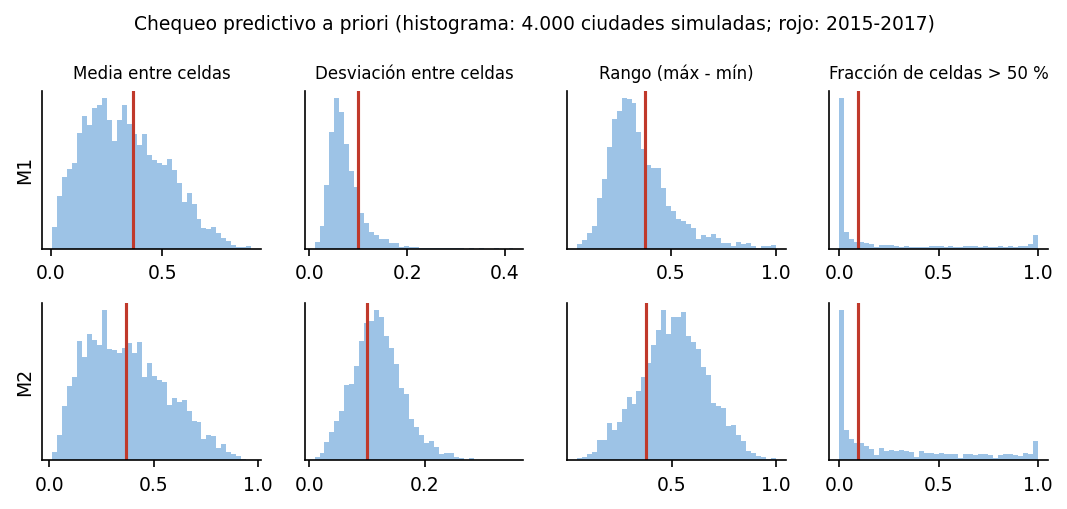

Guardado: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks\salidas\resultados\04_priors.json


In [38]:
from comun import *   # restaura los nombres comunes
from mcmc import M0, S0, IG
R = {}
# ---------------------------------------------------------------------------
# 7. Chequeo predictivo a priori (M1 y M2)
# ---------------------------------------------------------------------------
def stats_celdas(yc, nc):
    m_ = nc >= 30
    pr = yc[..., m_] / nc[m_]
    return np.stack([pr.mean(-1), pr.std(-1), pr.max(-1) - pr.min(-1), (pr > 0.5).mean(-1)], -1)


rng = np.random.default_rng(SEED + 7)
S = 4000
mpri = rng.beta(2, 4, S)
kpri = rng.gamma(2, 1 / 0.04, S)
tpri = rng.beta((mpri * kpri)[:, None], ((1 - mpri) * kpri)[:, None], (S, L * F))
st_m1 = stats_celdas(rng.binomial(n_tr, tpri), n_tr)

cy = (tr.groupby(["localidad", "franja", "anio"]).grave.agg(n="size", y="sum")
      .reindex(pd.MultiIndex.from_product([LOCS, FRANJAS, [2015, 2016, 2017]]), fill_value=0))
N3 = cy["n"].values.reshape(L, F, 3)
Y3 = cy["y"].values.reshape(L, F, 3)


def ig(a0, b0, size):
    return 1 / rng.gamma(a0, 1 / b0, size)


mu_p = rng.normal(M0, S0, S)
eta_pri = (mu_p[:, None, None, None]
           + np.sqrt(ig(*IG["a"], S))[:, None, None, None] * rng.standard_normal((S, L, 1, 1))
           + np.sqrt(ig(*IG["b"], S))[:, None, None, None] * rng.standard_normal((S, 1, F, 1))
           + np.sqrt(ig(*IG["g"], S))[:, None, None, None] * rng.standard_normal((S, L, F, 1))
           + np.sqrt(ig(*IG["d"], S))[:, None, None, None] * rng.standard_normal((S, 1, 1, 3)))
y2 = rng.binomial(N3[None], sp.expit(eta_pri)).sum(-1).reshape(S, -1)
st_m2 = stats_celdas(y2, n_tr)
st_obs = stats_celdas(y_tr[None], n_tr)[0]
nombres = ["Media entre celdas", "Desviación entre celdas", "Rango (máx - mín)", "Fracción de celdas > 50 %"]
fig, axs = plt.subplots(2, 4, figsize=(7.2, 3.4))
ppc = {}
for fila, (stt, nom) in enumerate(((st_m1, "M1"), (st_m2, "M2"))):
    for j in range(4):
        ax = axs[fila, j]
        ax.hist(stt[:, j], bins=40, color="#9dc3e6")
        ax.axvline(st_obs[j], color=ROJO)
        ax.set_yticks([])
        if fila == 0:
            ax.set_title(nombres[j], fontsize=8)
        if j == 0:
            ax.set_ylabel(nom)
        ppc[f"{nom}_{j}"] = float((stt[:, j] < st_obs[j]).mean())
fig.suptitle("Chequeo predictivo a priori (histograma: 4.000 ciudades simuladas; rojo: 2015-2017)", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "prior_predictivo.png")
plt.show()
R["ppc_percentil"] = ppc
R["ppc_obs"] = st_obs.tolist()
guardar_json(R, '04_priors.json')

## 5. M1: Beta-Binomial jerárquico (Gibbs + Metropolis-Hastings)
**Qué hace.** Define y corre el muestreador de M1 (4 cadenas, 5.000 de calentamiento y 20.000 guardadas), calcula R̂ y ESS con ArviZ y guarda los resúmenes que usan 07 y 08.

**Entradas.** `datos/siniestros_limpios.csv`.  
**Salidas.** `salidas/resultados/diagnosticos_M1.csv`, `05_M1.json`, `m1_resumen.npz`.

In [39]:
from comun import *   # restaura los nombres comunes
import time
import arviz as az
print('arviz', az.__version__)

arviz 0.23.4


### El algoritmo
Gibbs exacto para cada $\theta_c$ y paseo aleatorio de Metropolis-Hastings en $(\operatorname{logit} m, \log\kappa)$ con jacobiano. Este código es idéntico al de `mcmc.py` y al del script final.

In [40]:
# ---------------------------------------------------------------------------
# 3. Utilidades
# ---------------------------------------------------------------------------
def adaptar(logs, acc, it):
    """Ajusta la escala de la propuesta cada 100 iteraciones del calentamiento (objetivo ~0,3-0,44)."""
    if it < BURN and it > 0 and it % 100 == 0:
        tasa = acc / 100.0
        logs += np.where(tasa > 0.40, 0.15, np.where(tasa < 0.25, -0.15, 0.0))
        acc[...] = 0
    return logs


def resumen_az(post):
    idata = az.from_dict(posterior=post)
    s = az.summary(idata, kind="diagnostics")
    return s

# ---------------------------------------------------------------------------
# 4. M1: Beta-Binomial jerárquico (Gibbs + Metropolis-Hastings)
#   y_c | theta_c ~ Bin(n_c, theta_c)
#   theta_c | m, k ~ Beta(m k, (1-m) k)
#   m ~ Beta(2, 4),  k ~ Gamma(2, tasa)   (tasa 0,04 -> media 50)
# ---------------------------------------------------------------------------
def m1_logpost_hiper(u, v, theta, a_m=2.0, b_m=4.0, sh_k=2.0, rt_k=0.04):
    m, k = sp.expit(u), np.exp(v)
    al, be = m * k, (1 - m) * k
    lt, l1t = np.log(theta), np.log1p(-theta)
    ll = ((al - 1)[:, None] * lt + (be - 1)[:, None] * l1t).sum(1) - theta.shape[1] * sp.betaln(al, be)
    lp = (a_m - 1) * np.log(m) + (b_m - 1) * np.log1p(-m) + (sh_k - 1) * v - rt_k * k
    jac = np.log(m) + np.log1p(-m) + v
    return ll + lp + jac


def correr_m1(n, y, rt_k=0.04, a_m=2.0, b_m=4.0, seed=SEED, guardar_theta=True):
    rng = np.random.default_rng(seed)
    C = len(n)
    u = rng.normal(sp.logit(0.33), 0.3, K)
    v = np.log(rng.uniform(20, 100, K))
    logs = np.log(np.array([0.05, 0.15]))
    acc = np.zeros(2)
    out = {"m": np.empty((K, ITER)), "kappa": np.empty((K, ITER))}
    if guardar_theta:
        out["theta"] = np.empty((K, ITER, C), dtype=np.float32)
    nacc = 0
    for it in range(BURN + ITER):
        m, k = sp.expit(u), np.exp(v)
        # Paso de Gibbs: theta_c | m, k, y ~ Beta(m k + y_c, (1-m) k + n_c - y_c)
        theta = rng.beta((m * k)[:, None] + y, ((1 - m) * k)[:, None] + n - y)
        theta = np.clip(theta, 1e-12, 1 - 1e-12)
        # Paso de MH: (logit m, log k) con paseo aleatorio normal
        up = u + np.exp(logs[0]) * rng.standard_normal(K)
        vp = v + np.exp(logs[1]) * rng.standard_normal(K)
        lr = (m1_logpost_hiper(up, vp, theta, a_m, b_m, 2.0, rt_k)
              - m1_logpost_hiper(u, v, theta, a_m, b_m, 2.0, rt_k))
        ok = np.log(rng.uniform(size=K)) < lr
        u, v = np.where(ok, up, u), np.where(ok, vp, v)
        acc += ok.mean()
        logs = adaptar(logs, acc, it)
        if it >= BURN:
            j = it - BURN
            nacc += ok.sum()
            out["m"][:, j], out["kappa"][:, j] = sp.expit(u), np.exp(v)
            if guardar_theta:
                out["theta"][:, j] = theta
    out["acept"] = nacc / (K * ITER)
    return out

### Ajuste y diagnóstico

In [41]:
t0 = time.time()
m1 = correr_m1(n_tr, y_tr)
print(f'Tiempo: {time.time() - t0:.1f} s | aceptación MH: {m1["acept"]:.3f}')
diag1 = resumen_az({'m': m1['m'], 'kappa': m1['kappa'], 'theta': m1['theta'].astype(float)})
diag1.to_csv(RES / 'diagnosticos_M1.csv')
print('R-hat máx:', diag1.r_hat.max(), '| ESS bulk mín:', diag1.ess_bulk.min(), '| ESS tail mín:', diag1.ess_tail.min())
diag1.loc[['m', 'kappa']]

Tiempo: 2.3 s | aceptación MH: 0.320


R-hat máx: 1.0 | ESS bulk mín: 8961.0 | ESS tail mín: 12835.0


,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
m,0.000,0.000,"9,942.000","13,750.000",1.000
kappa,0.040,0.025,"8,961.000","12,835.000",1.000


In [42]:
th1 = m1['theta'].reshape(-1, L * F).astype(float)
i_usme = int(np.where((c_tr.localidad == 'Usme') & (c_tr.franja == 'Noche (18-24)'))[0][0])
np.savez_compressed(SALIDAS / 'm1_resumen.npz', m=m1['m'], kappa=m1['kappa'], theta_usme=m1['theta'][:, :, i_usme],
                    media=th1.mean(0), q05=np.quantile(th1, 0.05, 0), q95=np.quantile(th1, 0.95, 0),
                    p_top10=prob_top10(th1), thin20=th1[::20].astype(np.float32))
R = dict(acept=m1['acept'], m=m1['m'].mean(), m_ci=np.quantile(m1['m'], [0.05, 0.95]).tolist(),
         kappa=m1['kappa'].mean(), kappa_ci=np.quantile(m1['kappa'], [0.05, 0.95]).tolist(),
         rhat_max=diag1.r_hat.max(), ess_bulk_min=diag1.ess_bulk.min(), ess_tail_min=diag1.ess_tail.min())
print(limpio(R))
guardar_json(R, '05_M1.json')

{'acept': 0.32022, 'm': 0.3673, 'm_ci': [0.34862, 0.38623], 'kappa': 23.46104, 'kappa_ci': [17.66914, 30.12569], 'rhat_max': 1.0, 'ess_bulk_min': 8961.0, 'ess_tail_min': 12835.0}
Guardado: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks\salidas\resultados\05_M1.json


## 6. M2: regresión logística jerárquica (MH por componentes + Gibbs)
**Qué hace.** Define y corre el muestreador de M2 con efectos de localidad, franja, interacción y año; calcula R̂ y ESS y guarda la severidad predicha para un año nuevo, que es la base de la validación.

**Entradas.** `datos/siniestros_limpios.csv` (celdas localidad × franja × año 2015–2017).  
**Salidas.** `salidas/resultados/diagnosticos_M2.csv`, `06_M2.json`, `m2_resumen.npz`.

In [43]:
from comun import *   # restaura los nombres comunes
import time
import arviz as az
from mcmc import adaptar, resumen_az
print('arviz', az.__version__)

arviz 0.23.4


### El algoritmo
Metropolis-Hastings por componentes (vectorizado), movimientos de traslación entre niveles y Gibbs (Inversa-Gamma) para las varianzas. Idéntico a `mcmc.py` y al script final.

In [44]:
# ---------------------------------------------------------------------------
# 5. M2: logística jerárquica
#   y_{lft} | theta ~ Bin(n_{lft}, theta_{lft}),  logit theta = mu + a_l + b_f + g_lf + d_t
#   mu ~ N(logit(1/3), 1);  a_l ~ N(0, s2a);  b_f ~ N(0, s2b);  g_lf ~ N(0, s2g);  d_t ~ N(0, s2d)
#   s2a ~ IG(3, 0.5), s2b ~ IG(3, 0.5), s2g ~ IG(3, 0.1), s2d ~ IG(3, 0.05)
# ---------------------------------------------------------------------------
M0, S0 = sp.logit(1 / 3), 1.0
IG = {"a": (3.0, 0.5), "b": (3.0, 0.5), "g": (3.0, 0.1), "d": (3.0, 0.05)}


def correr_m2(Y, N, seed=SEED + 1):
    rng = np.random.default_rng(seed)
    T = Y.shape[2]
    mu = rng.normal(M0, 0.2, K)
    a = rng.normal(0, 0.2, (K, L))
    b = rng.normal(0, 0.2, (K, F))
    g = rng.normal(0, 0.1, (K, L, F))
    d = rng.normal(0, 0.05, (K, T))
    s2 = {key: np.full(K, IG[key][1] / (IG[key][0] - 1)) for key in IG}

    def eta_de(mu, a, b, g, d):
        return mu[:, None, None, None] + a[:, :, None, None] + b[:, None, :, None] + g[..., None] + d[:, None, None, :]

    def ll_de(eta):
        return Y * eta - N * np.logaddexp(0.0, eta)

    escalas = {"mu": np.full(1, np.log(0.02)), "a": np.full(L, np.log(0.05)), "b": np.full(F, np.log(0.02)),
               "g": np.full((L, F), np.log(0.05)), "d": np.full(T, np.log(0.02)),
               "sh_mu_a": np.full(1, np.log(0.1)), "sh_mu_b": np.full(1, np.log(0.1)),
               "sh_mu_d": np.full(1, np.log(0.1)), "sh_a_g": np.full(L, np.log(0.1)),
               "sh_b_g": np.full(F, np.log(0.1))}
    acc = {k_: np.zeros_like(v_) for k_, v_ in escalas.items()}
    tasas = {k_: np.zeros_like(v_) for k_, v_ in escalas.items()}
    out = {k_: [] for k_ in ["mu", "sigma_a", "sigma_b", "sigma_g", "sigma_d"]}
    out["theta_new"] = np.empty((K, ITER, L * F), dtype=np.float32)
    out["a"] = np.empty((K, ITER, L), dtype=np.float32)
    out["b"] = np.empty((K, ITER, F), dtype=np.float32)
    out["d"] = np.empty((K, ITER, T), dtype=np.float32)

    eta = eta_de(mu, a, b, g, d)
    ll = ll_de(eta)
    for it in range(BURN + ITER):
        # --- mu
        e = np.exp(escalas["mu"][0]) * rng.standard_normal(K)
        eta_p = eta + e[:, None, None, None]
        llp = ll_de(eta_p)
        lr = (llp - ll).sum((1, 2, 3)) - ((mu + e - M0) ** 2 - (mu - M0) ** 2) / (2 * S0 ** 2)
        ok = np.log(rng.uniform(size=K)) < lr
        mu = np.where(ok, mu + e, mu)
        eta = np.where(ok[:, None, None, None], eta_p, eta)
        ll = np.where(ok[:, None, None, None], llp, ll)
        acc["mu"] += ok.mean()
        tasas["mu"] += ok.mean()
        # --- a_l (20 componentes; cada una solo afecta a sus filas)
        e = np.exp(escalas["a"]) * rng.standard_normal((K, L))
        eta_p = eta + e[:, :, None, None]
        llp = ll_de(eta_p)
        lr = (llp - ll).sum((2, 3)) - ((a + e) ** 2 - a ** 2) / (2 * s2["a"][:, None])
        ok = np.log(rng.uniform(size=(K, L))) < lr
        a = np.where(ok, a + e, a)
        m4 = ok[:, :, None, None]
        eta, ll = np.where(m4, eta_p, eta), np.where(m4, llp, ll)
        acc["a"] += ok.mean(0)
        tasas["a"] += ok.mean(0)
        # --- b_f
        e = np.exp(escalas["b"]) * rng.standard_normal((K, F))
        eta_p = eta + e[:, None, :, None]
        llp = ll_de(eta_p)
        lr = (llp - ll).sum((1, 3)) - ((b + e) ** 2 - b ** 2) / (2 * s2["b"][:, None])
        ok = np.log(rng.uniform(size=(K, F))) < lr
        b = np.where(ok, b + e, b)
        m4 = ok[:, None, :, None]
        eta, ll = np.where(m4, eta_p, eta), np.where(m4, llp, ll)
        acc["b"] += ok.mean(0)
        tasas["b"] += ok.mean(0)
        # --- g_lf (80 componentes)
        e = np.exp(escalas["g"]) * rng.standard_normal((K, L, F))
        eta_p = eta + e[..., None]
        llp = ll_de(eta_p)
        lr = (llp - ll).sum(3) - ((g + e) ** 2 - g ** 2) / (2 * s2["g"][:, None, None])
        ok = np.log(rng.uniform(size=(K, L, F))) < lr
        g = np.where(ok, g + e, g)
        m4 = ok[..., None]
        eta, ll = np.where(m4, eta_p, eta), np.where(m4, llp, ll)
        acc["g"] += ok.mean(0)
        tasas["g"] += ok.mean(0)
        # --- d_t
        e = np.exp(escalas["d"]) * rng.standard_normal((K, T))
        eta_p = eta + e[:, None, None, :]
        llp = ll_de(eta_p)
        lr = (llp - ll).sum((1, 2)) - ((d + e) ** 2 - d ** 2) / (2 * s2["d"][:, None])
        ok = np.log(rng.uniform(size=(K, T))) < lr
        d = np.where(ok, d + e, d)
        m4 = ok[:, None, None, :]
        eta, ll = np.where(m4, eta_p, eta), np.where(m4, llp, ll)
        acc["d"] += ok.mean(0)
        tasas["d"] += ok.mean(0)
        # --- Traslaciones (la verosimilitud no cambia; solo la razón de priors)
        #     mu + c, efectos - c  : reduce la correlación entre el intercepto y los efectos
        for clave, vec, s2k in (("sh_mu_a", a, "a"), ("sh_mu_b", b, "b"), ("sh_mu_d", d, "d")):
            c = np.exp(escalas[clave][0]) * rng.standard_normal(K)
            mu_p, vec_p = mu + c, vec - c[:, None]
            lr = (-((mu_p - M0) ** 2 - (mu - M0) ** 2) / (2 * S0 ** 2)
                  - ((vec_p ** 2).sum(1) - (vec ** 2).sum(1)) / (2 * s2[s2k]))
            ok = np.log(rng.uniform(size=K)) < lr
            mu = np.where(ok, mu_p, mu)
            vec[...] = np.where(ok[:, None], vec_p, vec)
            acc[clave] += ok.mean()
            tasas[clave] += ok.mean()
        #     a_l + c_l, g_l. - c_l   y   b_f + c_f, g_.f - c_f
        c = np.exp(escalas["sh_a_g"]) * rng.standard_normal((K, L))
        a_p, g_p = a + c, g - c[:, :, None]
        lr = (-((a_p ** 2 - a ** 2) / (2 * s2["a"][:, None]))
              - ((g_p ** 2 - g ** 2).sum(2) / (2 * s2["g"][:, None])))
        ok = np.log(rng.uniform(size=(K, L))) < lr
        a, g = np.where(ok, a_p, a), np.where(ok[:, :, None], g_p, g)
        acc["sh_a_g"] += ok.mean(0)
        tasas["sh_a_g"] += ok.mean(0)
        c = np.exp(escalas["sh_b_g"]) * rng.standard_normal((K, F))
        b_p, g_p = b + c, g - c[:, None, :]
        lr = (-((b_p ** 2 - b ** 2) / (2 * s2["b"][:, None]))
              - ((g_p ** 2 - g ** 2).sum(1) / (2 * s2["g"][:, None])))
        ok = np.log(rng.uniform(size=(K, F))) < lr
        b, g = np.where(ok, b_p, b), np.where(ok[:, None, :], g_p, g)
        acc["sh_b_g"] += ok.mean(0)
        tasas["sh_b_g"] += ok.mean(0)
        # --- Gibbs para las varianzas: s2 | x ~ IG(a0 + J/2, b0 + sum(x^2)/2)
        for key, x in (("a", a), ("b", b), ("g", g.reshape(K, -1)), ("d", d)):
            a0, b0 = IG[key]
            s2[key] = 1.0 / rng.gamma(a0 + x.shape[1] / 2, 1.0 / (b0 + (x ** 2).sum(1) / 2))
        # --- adaptación de escalas durante el calentamiento
        if 0 < it < BURN and it % 100 == 0:
            for k_ in escalas:
                tasa = acc[k_] / 100.0
                escalas[k_] = escalas[k_] + np.where(tasa > 0.44, 0.15, np.where(tasa < 0.25, -0.15, 0.0))
                acc[k_][...] = 0
        if it == BURN - 1:
            for k_ in tasas:
                tasas[k_][...] = 0
        if it >= BURN:
            j = it - BURN
            out["mu"].append(mu.copy())
            for key in "abgd":
                out["sigma_" + key].append(np.sqrt(s2[key]))
            # severidad esperada en un año nuevo: d_new ~ N(0, s2d)
            d_new = np.sqrt(s2["d"]) * rng.standard_normal(K)
            eta_new = mu[:, None, None] + a[:, :, None] + b[:, None, :] + g + d_new[:, None, None]
            out["theta_new"][:, j] = sp.expit(eta_new).reshape(K, -1)
            out["a"][:, j], out["b"][:, j], out["d"][:, j] = a, b, d
    for k_ in ["mu", "sigma_a", "sigma_b", "sigma_g", "sigma_d"]:
        out[k_] = np.stack(out[k_], axis=1)
    out["acept"] = {k_: float(np.mean(v_) / ITER) for k_, v_ in tasas.items()}
    return out

### Ajuste y diagnóstico

In [45]:
t0 = time.time()
m2 = correr_m2(Y3, N3)
print(f'Tiempo: {time.time() - t0:.1f} s')
print('Aceptación por bloque:', limpio(m2['acept']))
diag2 = resumen_az({'mu': m2['mu'], 'sigma_a': m2['sigma_a'], 'sigma_b': m2['sigma_b'], 'sigma_g': m2['sigma_g'],
                    'sigma_d': m2['sigma_d'], 'theta_new': m2['theta_new'].astype(float)})
diag2.to_csv(RES / 'diagnosticos_M2.csv')
print('R-hat máx:', diag2.r_hat.max(), '| ESS bulk mín:', diag2.ess_bulk.min(), '| ESS tail mín:', diag2.ess_tail.min())
diag2.loc[['mu', 'sigma_a', 'sigma_b', 'sigma_g', 'sigma_d']]

Tiempo: 12.3 s
Aceptación por bloque: {'mu': 0.38698, 'a': 0.36603, 'b': 0.37367, 'g': 0.36347, 'd': 0.36549, 'sh_mu_a': 0.32803, 'sh_mu_b': 0.38554, 'sh_mu_d': 0.36223, 'sh_a_g': 0.3563, 'sh_b_g': 0.34888}


R-hat máx: 1.0 | ESS bulk mín: 9204.0 | ESS tail mín: 21772.0


,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu,0.002,0.001,"17,868.000","24,775.000",1.000
sigma_a,0.000,0.000,"37,827.000","57,573.000",1.000
sigma_b,0.000,0.001,"49,307.000","59,204.000",1.000
sigma_g,0.000,0.000,"9,204.000","21,772.000",1.000
sigma_d,0.000,0.000,"45,333.000","55,394.000",1.000


In [46]:
th2 = m2['theta_new'].reshape(-1, L * F).astype(float)
w = n_tr / n_tr.sum()
pmay2 = (th2 > (th2 * w).sum(1, keepdims=True)).mean(0)
bc = m2['b'].reshape(-1, F); bc = bc - bc.mean(1, keepdims=True)
dc = m2['d'].reshape(-1, 3)
np.savez_compressed(SALIDAS / 'm2_resumen.npz', mu=m2['mu'], sigma_a=m2['sigma_a'], sigma_b=m2['sigma_b'],
                    sigma_g=m2['sigma_g'], sigma_d=m2['sigma_d'], media=th2.mean(0), q05=np.quantile(th2, 0.05, 0),
                    q95=np.quantile(th2, 0.95, 0), p_top10=prob_top10(th2), p_mayor_ciudad=pmay2,
                    thin20=th2[::20].astype(np.float32))
R = {k: dict(media=m2[k].mean(), ci=np.quantile(m2[k], [0.05, 0.95]).tolist()) for k in ['mu', 'sigma_a', 'sigma_b', 'sigma_g', 'sigma_d']}
R['franja_OR'] = {FRANJAS[f]: dict(OR=np.exp(bc[:, f]).mean(), ci=np.exp(np.quantile(bc[:, f], [0.05, 0.95])).tolist()) for f in range(F)}
R['anio_d'] = {str(2015 + t): dc[:, t].mean() for t in range(3)}
R['acept'] = m2['acept']
R.update(rhat_max=diag2.r_hat.max(), ess_bulk_min=diag2.ess_bulk.min(), ess_tail_min=diag2.ess_tail.min())
print(limpio({k: R[k] for k in ['sigma_a', 'sigma_b', 'sigma_g', 'sigma_d', 'franja_OR']}))
guardar_json(R, '06_M2.json')

{'sigma_a': {'media': 0.42785, 'ci': [0.33305, 0.54963]}, 'sigma_b': {'media': 0.37429, 'ci': [0.25025, 0.55945]}, 'sigma_g': {'media': 0.15993, 'ci': [0.13098, 0.19352]}, 'sigma_d': {'media': 0.1405, 'ci': [0.09102, 0.21656]}, 'franja_OR': {'Madrugada (0-6)': {'OR': 1.09131, 'ci': [1.02419, 1.1605]}, 'Mañana (6-12)': {'OR': 0.952, 'ci': [0.89968, 1.00712]}, 'Tarde (12-18)': {'OR': 0.84405, 'ci': [0.79737, 0.89248]}, 'Noche (18-24)': {'OR': 1.14323, 'ci': [1.07903, 1.21006]}}}
Guardado: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks\salidas\resultados\06_M2.json


## 7. Convergencia, resultados por celda y validación con 2018–2019
**Qué hace.** Grafica la convergencia, arma la tabla por celda (severidad, intervalos, P(top 10), niveles de prioridad), valida contra 2018–2019 (Spearman, Brier, log-loss, top 10, lpd, cobertura), revisa la equidad del error y la capacidad de 10 celdas, y comprueba que las cifras coinciden con el informe.

**Entradas.** `salidas/m1_resumen.npz` (de 05), `salidas/m2_resumen.npz` (de 06), `datos/siniestros_limpios.csv`.  
**Salidas.** `salidas/figuras/trazas.png, autocorr_densidades.png, encogimiento.png, top20_forest.png, validacion.png`; `salidas/resultados/celdas_posterior.csv, validacion_2018_2019.csv, 07_validacion.json`.

In [47]:
from comun import *   # restaura los nombres comunes
a1, a2 = np.load(SALIDAS / 'm1_resumen.npz'), np.load(SALIDAS / 'm2_resumen.npz')
p1, p2 = a1['media'], a2['media']
R = {"datos": dict(p_tr=y_tr.sum() / n_tr.sum(), p_te=y_te.sum() / n_te.sum())}

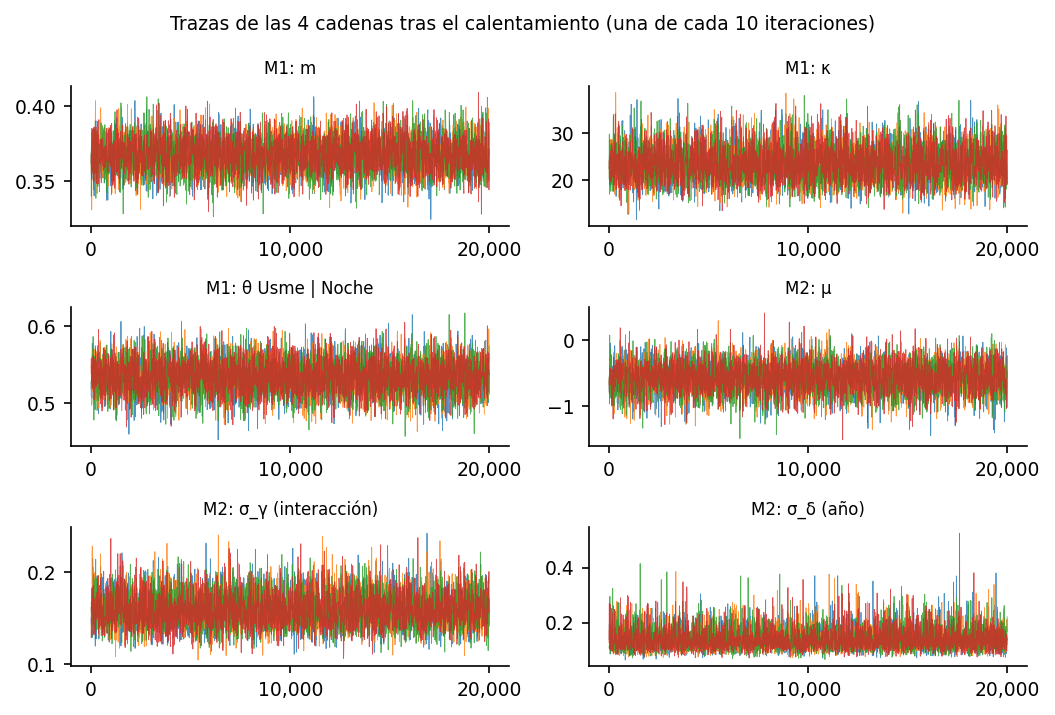

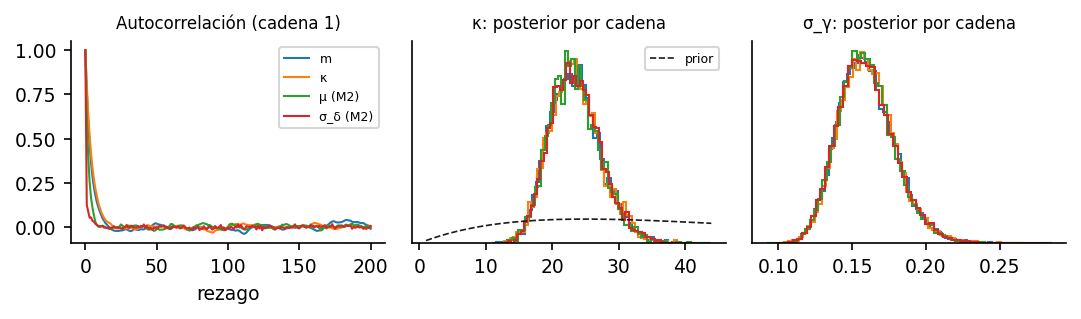

In [48]:
# Figura 6: trazas; Figura 7: autocorrelación y densidades por cadena
fig, axs = plt.subplots(3, 2, figsize=(7.2, 4.8))
series = [("M1: m", a1["m"]), ("M1: κ", a1["kappa"]), ("M1: θ Usme | Noche", a1["theta_usme"]),
          ("M2: μ", a2["mu"]), ("M2: σ_γ (interacción)", a2["sigma_g"]), ("M2: σ_δ (año)", a2["sigma_d"])]
colores = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
for ax, (tit, x) in zip(axs.ravel(), series):
    for c in range(K):
        ax.plot(x[c, ::10], lw=0.4, color=colores[c], alpha=0.8)
    ax.set_title(tit, fontsize=8)
    ax.set_xticks([0, ITER // 20, ITER // 10], ["0", f"{ITER // 2:,}", f"{ITER:,}"])
fig.suptitle("Trazas de las 4 cadenas tras el calentamiento (una de cada 10 iteraciones)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "trazas.png"); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.2))
for tit, x in (("m", a1["m"]), ("κ", a1["kappa"]), ("μ (M2)", a2["mu"]), ("σ_δ (M2)", a2["sigma_d"])):
    z = x[0] - x[0].mean()
    ac = np.correlate(z, z, "full")[len(z) - 1:len(z) + 200] / (z.var() * len(z))
    axs[0].plot(ac, lw=1, label=tit)
axs[0].set_title("Autocorrelación (cadena 1)", fontsize=8); axs[0].legend(fontsize=6); axs[0].set_xlabel("rezago")
for c in range(K):
    axs[1].hist(a1["kappa"][c], bins=60, histtype="step", density=True, color=colores[c])
    axs[2].hist(a2["sigma_g"][c], bins=60, histtype="step", density=True, color=colores[c])
xs = np.linspace(1, a1["kappa"].max(), 200)
axs[1].plot(xs, st.gamma(2, scale=25).pdf(xs), "k--", lw=0.8, label="prior")
axs[1].set_title("κ: posterior por cadena", fontsize=8); axs[1].legend(fontsize=6)
axs[2].set_title("σ_γ: posterior por cadena", fontsize=8)
for ax in axs[1:]:
    ax.set_yticks([])
fig.tight_layout(); fig.savefig(FIG / "autocorr_densidades.png"); plt.show()

In [49]:
# Tabla por celda: severidad, intervalos, P(top 10), niveles de prioridad
pt1, pt2, pmay2 = a1['p_top10'], a2['p_top10'], a2['p_mayor_ciudad']
nivel = np.where(pmay2 > 0.95, "Alta", np.where(pmay2 < 0.05, "Baja", "Intermedia"))
nivel = np.where(n_tr < 30, "No concluyente", nivel)
tab = c_tr.rename(columns={"n": "n_2015_2017", "y": "graves_2015_2017"}).copy()
tab["p_cruda"] = p_cruda_tr
tab["M1_media"], tab["M1_q05"], tab["M1_q95"] = p1, a1['q05'], a1['q95']
tab["M2_media"], tab["M2_q05"], tab["M2_q95"] = p2, a2['q05'], a2['q95']
tab["M2_P_top10"], tab["M1_P_top10"] = pt2, pt1
tab["M2_P_mayor_ciudad"], tab["nivel"] = pmay2, nivel
tab["n_2018_2019"], tab["graves_2018_2019"] = n_te, y_te
tab["p_obs_2018_2019"] = obs_te
tab["elegible"] = eleg
tab["rank_conteo"] = (-y_tr).argsort().argsort() + 1
tab["rank_M2"] = (-p2).argsort().argsort() + 1
tab.to_csv(RES / "celdas_posterior.csv", index=False, encoding="utf-8-sig")
R["niveles"] = tab.nivel.value_counts().to_dict()
R["prioridad1_P_top10_ge_05"] = int((pt2 >= 0.5).sum())
R["P_top10_mayor_09"] = int((pt2 > 0.9).sum())
R["P_top10_entre_01_05"] = int(((pt2 >= 0.1) & (pt2 < 0.5)).sum())
R["prioridad2"] = int(((nivel == "Alta") & (pt2 < 0.5)).sum())
R["menor_n_en_prioridad1"] = int(n_tr[pt2 >= 0.5].min())
R["rho_M2_vs_conteo"] = float(st.spearmanr(p2[eleg], y_tr[eleg])[0])
R["rho_M1_vs_M2"] = float(st.spearmanr(p1[eleg], p2[eleg])[0])
R["encogimiento_max_pp_M2"] = float(np.max(np.abs(p2 - p_cruda_tr)[n_tr >= 30]) * 100)
R["rango_M2"] = [tab.loc[eleg].sort_values("M2_media").iloc[[0, -1]][["localidad", "franja", "M2_media", "M2_q05", "M2_q95"]].round(3).to_dict("records")]
print(limpio({k: R[k] for k in R if k != "rango_M2"}))
tab.sort_values("M2_media", ascending=False).head(10)[["localidad", "franja", "n_2015_2017", "M2_media", "M2_q05", "M2_q95", "M2_P_top10", "p_obs_2018_2019", "rank_conteo"]].round(3)

{'datos': {'p_tr': 0.32838, 'p_te': 0.36101}, 'niveles': {'Alta': 41, 'Baja': 24, 'Intermedia': 10, 'No concluyente': 5}, 'prioridad1_P_top10_ge_05': 9, 'P_top10_mayor_09': 5, 'P_top10_entre_01_05': 7, 'prioridad2': 32, 'menor_n_en_prioridad1': 502, 'rho_M2_vs_conteo': -0.19035, 'rho_M1_vs_M2': 0.99058, 'encogimiento_max_pp_M2': 4.53443}


,localidad,franja,n_2015_2017,M2_media,M2_q05,M2_q95,M2_P_top10,p_obs_2018_2019,rank_conteo
47,Rafael Uribe Uribe,Noche (18-24),705,0.547,0.473,0.619,1.000,0.533,37
79,Usme,Noche (18-24),502,0.534,0.458,0.608,0.990,0.525,54
51,San Cristóbal,Noche (18-24),636,0.531,0.457,0.605,0.993,0.548,45
49,San Cristóbal,Mañana (6-12),808,0.521,0.448,0.594,0.986,0.573,34
50,San Cristóbal,Tarde (12-18),832,0.510,0.437,0.582,0.923,0.484,33
11,Bosa,Noche (18-24),1172,0.501,0.429,0.571,0.849,0.488,18
46,Rafael Uribe Uribe,Tarde (12-18),891,0.496,0.423,0.568,0.740,0.507,31
45,Rafael Uribe Uribe,Mañana (6-12),807,0.494,0.421,0.566,0.681,0.565,35
19,Ciudad Bolívar,Noche (18-24),1031,0.487,0.416,0.559,0.545,0.522,24
3,Antonio Nariño,Noche (18-24),494,0.481,0.406,0.557,0.406,0.523,57


In [50]:
# Tabla 2 del informe: validación con 2018-2019 (se mira una sola vez)
val = {"Ciudad (agrupamiento completo)": metricas(p_city),
       "Proporción cruda (sin agrupamiento)": metricas(p_cruda_tr),
       "M1 Beta-Binomial jerárquico": metricas(p1, theta_thin=a1["thin20"]),
       "M2 Logística jerárquica": metricas(p2, theta_thin=a2["thin20"])}
rho_conteo = float(st.spearmanr(y_tr[eleg], obs_te[eleg])[0])
top_c = set(idx_e[np.argsort(-y_tr[idx_e])[:10]])
top_o = set(idx_e[np.argsort(-obs_te[idx_e])[:10]])
val["Conteo de graves (criterio actual)"] = dict(spearman=rho_conteo, top10=len(top_c & top_o))
R["validacion"] = val
cr = val["Proporción cruda (sin agrupamiento)"]["brier"]
R["criterios"] = {k: dict(spearman_ok=val[k]["spearman"] >= 0.90, brier_ok=val[k]["brier"] <= cr, top10_ok=val[k]["top10"] >= 6)
                  for k in ("M1 Beta-Binomial jerárquico", "M2 Logística jerárquica")}
shift = sp.logit(y_te.sum() / n_te.sum()) - sp.logit(y_tr.sum() / n_tr.sum())
R["brier_M2_nivel_corregido"] = metricas(sp.expit(sp.logit(p2) + shift))["brier"]
R["brier_cruda_nivel_corregido"] = metricas(sp.expit(sp.logit(np.clip(p_cruda_tr, 1e-3, 1 - 1e-3)) + shift))["brier"]
pd.DataFrame(val).T.to_csv(RES / "validacion_2018_2019.csv", encoding="utf-8-sig")
print("Criterios de éxito:", R["criterios"])
pd.DataFrame(val).T[["brier", "logloss", "spearman", "top10", "lpd", "cobertura90"]].round(5)

Criterios de éxito: {'M1 Beta-Binomial jerárquico': {'spearman_ok': True, 'brier_ok': True, 'top10_ok': True}, 'M2 Logística jerárquica': {'spearman_ok': True, 'brier_ok': True, 'top10_ok': True}}


C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks\comun.py:94: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = float(st.spearmanr(p[eleg_], obs[eleg_])[0])


,brier,logloss,spearman,top10,lpd,cobertura90
Ciudad (agrupamiento completo),0.232,0.656,NaN,1.000,NaN,NaN
Proporción cruda (sin agrupamiento),0.222,0.635,0.921,6.000,NaN,NaN
M1 Beta-Binomial jerárquico,0.222,0.635,0.923,6.000,-429.682,0.494
M2 Logística jerárquica,0.222,0.634,0.933,6.000,-375.297,0.949
Conteo de graves (criterio actual),NaN,NaN,-0.329,0.000,NaN,NaN


In [51]:
# Equidad del error (umbral de 3 puntos fijado en el Avance 2) y capacidad de 10 celdas
v = val["M2 Logística jerárquica"]
eq = pd.DataFrame({g: [100 * v[f"mae_{g}"], 100 * v[f"mae_no_{g}"], 100 * (v[f"mae_{g}"] - v[f"mae_no_{g}"]), 100 * v[f"sesgo_{g}"]]
                   for g in ("sur", "noche_madrug", "pequenas")}, index=["MAE grupo", "MAE resto", "diferencia (pp)", "sesgo grupo"]).round(2)
print(f"Piso binomial: pequeñas {100*v['piso_mae_pequenas']:.2f} pp, grandes {100*v['piso_mae_grandes']:.2f} pp; "
      f"exceso sobre el piso: {100*(v['mae_pequenas']-v['piso_mae_pequenas']):.2f} vs {100*(v['mae_no_pequenas']-v['piso_mae_grandes']):.2f} pp")
e = tab[tab.elegible]
cap = {}
for nom, s_ in (("M2", e.nlargest(10, "M2_media")), ("conteo", e.nlargest(10, "graves_2015_2017"))):
    cap[nom] = dict(siniestros=int(s_.n_2018_2019.sum()), graves=int(s_.graves_2018_2019.sum()),
                    pct=s_.graves_2018_2019.sum() / s_.n_2018_2019.sum())
cap["coinciden"] = len(set(e.nlargest(10, "M2_media").index) & set(e.nlargest(10, "graves_2015_2017").index))
R["capacidad_10_celdas"] = cap
print("Capacidad 10 celdas (2018-2019):", limpio(cap))
eq

Piso binomial: pequeñas 2.99 pp, grandes 1.29 pp; exceso sobre el piso: 3.70 vs 2.16 pp
Capacidad 10 celdas (2018-2019): {'M2': {'siniestros': 6048, 'graves': 3169, 'pct': 0.52397}, 'conteo': {'siniestros': 21016, 'graves': 7755, 'pct': 0.369}, 'coinciden': 0}


,sur,noche_madrug,pequenas
MAE grupo,3.760,4.640,6.690
MAE resto,4.320,3.660,3.450
diferencia (pp),-0.560,0.980,3.240
sesgo grupo,-2.640,-4.080,-5.930


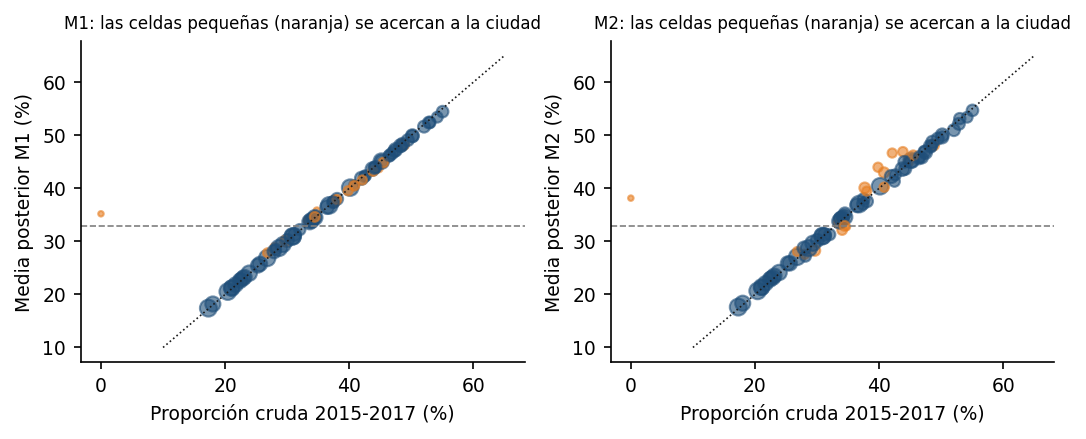

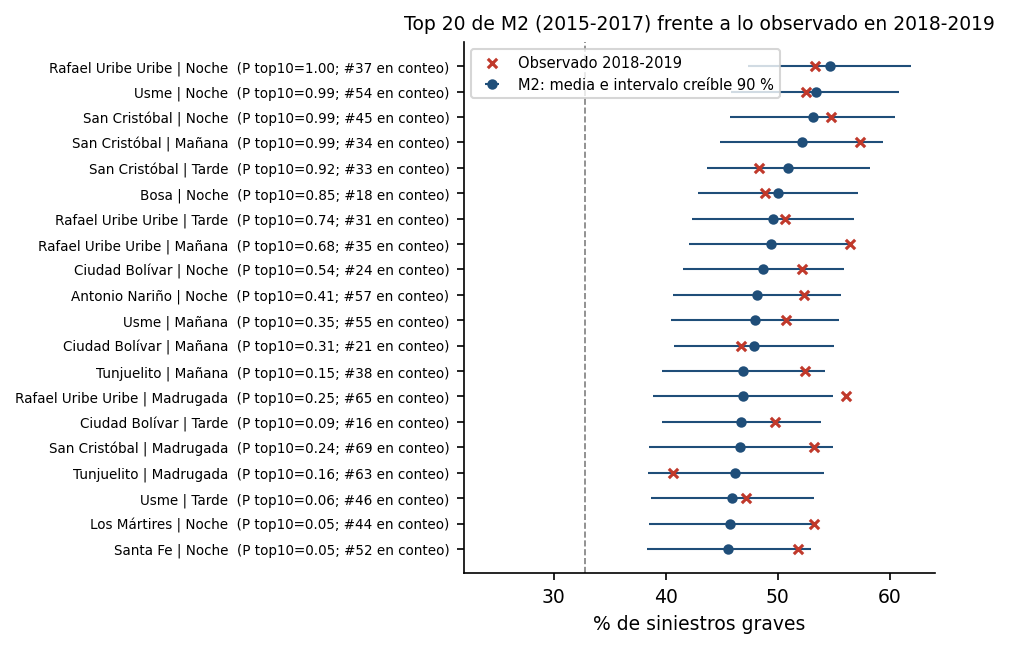

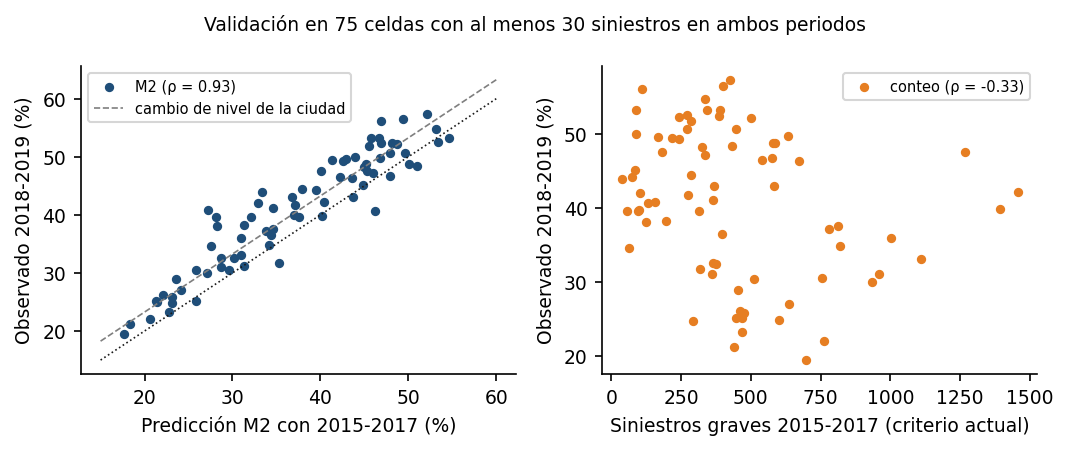

In [52]:
# Figura de encogimiento
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0))
for ax, p_, nom in ((axs[0], p1, "M1"), (axs[1], p2, "M2")):
    s_ = 6 + 60 * np.sqrt(n_tr / n_tr.max())
    ax.scatter(100 * p_cruda_tr[n_tr > 0], 100 * p_[n_tr > 0], s=s_[n_tr > 0], alpha=0.6,
               c=np.where(n_tr[n_tr > 0] < 500, NARANJA, AZUL))
    ax.plot([10, 65], [10, 65], "k:", lw=0.8)
    ax.axhline(100 * p_city[0], color=GRIS, ls="--", lw=0.8)
    ax.set_xlabel("Proporción cruda 2015-2017 (%)")
    ax.set_ylabel(f"Media posterior {nom} (%)")
    ax.set_title(f"{nom}: las celdas pequeñas (naranja) se acercan a la ciudad", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "encogimiento.png")
plt.show()

# Forest plot del top 20 de M2
top20 = tab.sort_values("M2_media", ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.4, 4.4))
yy = np.arange(len(top20))
ax.errorbar(100 * top20.M2_media, yy, xerr=[100 * (top20.M2_media - top20.M2_q05), 100 * (top20.M2_q95 - top20.M2_media)],
            fmt="o", color=AZUL, ms=4, lw=1, label="M2: media e intervalo creíble 90 %")
ax.scatter(100 * top20.p_obs_2018_2019, yy, marker="x", color=ROJO, s=20, zorder=3, label="Observado 2018-2019")
ax.set_yticks(yy, [f"{a} | {b.split(' ')[0]}  (P top10={p:.2f}; #{r} en conteo)"
                   for a, b, p, r in zip(top20.localidad, top20.franja, top20.M2_P_top10, top20.rank_conteo)], fontsize=6.5)
ax.axvline(100 * R["datos"]["p_tr"], color=GRIS, ls="--", lw=0.8)
ax.set_xlabel("% de siniestros graves")
ax.legend(fontsize=7, loc="upper left")
ax.set_xlim(22, 64)
ax.set_title("Top 20 de M2 (2015-2017) frente a lo observado en 2018-2019", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "top20_forest.png")
plt.show()

# Figura de validación: predicción vs observado y orden por conteo
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0))
e = eleg
axs[0].scatter(100 * p2[e], 100 * obs_te[e], s=12, color=AZUL, label=f"M2 (ρ = {val['M2 Logística jerárquica']['spearman']:.2f})")
axs[0].plot([15, 60], [15, 60], "k:", lw=0.8)
axs[0].plot([15, 60], [15 + 100 * (R['datos']['p_te'] - R['datos']['p_tr']), 60 + 100 * (R['datos']['p_te'] - R['datos']['p_tr'])],
            color=GRIS, ls="--", lw=0.8, label="cambio de nivel de la ciudad")
axs[0].set_xlabel("Predicción M2 con 2015-2017 (%)")
axs[0].set_ylabel("Observado 2018-2019 (%)")
axs[0].legend(fontsize=7)
axs[1].scatter(y_tr[e], 100 * obs_te[e], s=12, color=NARANJA, label=f"conteo (ρ = {rho_conteo:.2f})")
axs[1].set_xlabel("Siniestros graves 2015-2017 (criterio actual)")
axs[1].set_ylabel("Observado 2018-2019 (%)")
axs[1].legend(fontsize=7)
fig.suptitle(f"Validación en {e.sum()} celdas con al menos 30 siniestros en ambos periodos", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "validacion.png")
plt.show()

In [53]:
# Verificación contra el informe (si algo no coincide, la celda falla)
m2v = val["M2 Logística jerárquica"]
esperado = {"Spearman M2": (round(m2v["spearman"], 3), 0.933), "Brier M2": (round(m2v["brier"], 5), 0.22169),
            "Top 10 M2": (m2v["top10"], 6), "Cobertura IC90 M2": (round(m2v["cobertura90"], 3), 0.949),
            "Spearman M1": (round(val["M1 Beta-Binomial jerárquico"]["spearman"], 3), 0.923),
            "Brier cruda": (round(cr, 5), 0.22181), "Spearman conteo": (round(rho_conteo, 3), -0.329),
            "Capacidad M2": ((cap["M2"]["siniestros"], cap["M2"]["graves"]), (6048, 3169)),
            "Capacidad conteo": ((cap["conteo"]["siniestros"], cap["conteo"]["graves"]), (21016, 7755))}
for k, (obtenido, informe) in esperado.items():
    print(f"{k:20s} notebook={obtenido}  informe={informe}  {'OK' if obtenido == informe else 'DIFERENTE'}")
assert all(o == i for o, i in esperado.values()), "Alguna cifra no coincide con el informe"
guardar_json(R, "07_validacion.json")

Spearman M2          notebook=0.933  informe=0.933  OK
Brier M2             notebook=0.22169  informe=0.22169  OK
Top 10 M2            notebook=6  informe=6  OK
Cobertura IC90 M2    notebook=0.949  informe=0.949  OK
Spearman M1          notebook=0.923  informe=0.923  OK
Brier cruda          notebook=0.22181  informe=0.22181  OK
Spearman conteo      notebook=-0.329  informe=-0.329  OK
Capacidad M2         notebook=(6048, 3169)  informe=(6048, 3169)  OK
Capacidad conteo     notebook=(21016, 7755)  informe=(21016, 7755)  OK
Guardado: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks\salidas\resultados\07_validacion.json


## 8. Las cinco sensibilidades fijadas en el Avance 2
**Qué hace.** Repite M1 con la prior de κ centrada en 10 y en 300, con franjas de tres horas y con solo siniestros con muertos, y compara el orden de M2 con 2020 (Tabla 3 del informe).

**Entradas.** `datos/siniestros_limpios.csv`; `salidas/m1_resumen.npz` y `m2_resumen.npz`.  
**Salidas.** `salidas/resultados/08_sensibilidades.json`.

In [54]:
from comun import *   # restaura los nombres comunes
from mcmc import correr_m1
a1, a2 = np.load(SALIDAS / 'm1_resumen.npz'), np.load(SALIDAS / 'm2_resumen.npz')
p1, p2 = a1['media'], a2['media']
R = {}

In [55]:
# ---------------------------------------------------------------------------
# 11. Cinco sensibilidades fijadas en el Avance 2
# ---------------------------------------------------------------------------
sens = {}
for nom, rt in (("kappa centrada en 10", 2 / 10), ("kappa centrada en 300", 2 / 300)):
    o = correr_m1(n_tr, y_tr, rt_k=rt, seed=SEED + 11)
    mt = metricas(o["theta"].reshape(-1, L * F).mean(0))
    sens[nom] = dict(spearman=mt["spearman"], brier=mt["brier"], top10=mt["top10"],
                     kappa=float(o["kappa"].mean()),
                     rho_vs_M1=float(st.spearmanr(o["theta"].reshape(-1, L * F).mean(0)[eleg], p1[eleg])[0]))
# franjas de tres horas
c3_tr = celdas(tr, "franja3h", FR3)
c3_te = celdas(te, "franja3h", FR3)
o = correr_m1(c3_tr.n.values, c3_tr.y.values, seed=SEED + 12)
p3 = o["theta"].reshape(-1, len(c3_tr)).mean(0)
el3 = (c3_tr.n.values >= 30) & (c3_te.n.values >= 30)
ob3 = np.where(c3_te.n > 0, c3_te.y / np.maximum(c3_te.n, 1), np.nan)
cr3 = np.where(c3_tr.n > 0, c3_tr.y / np.maximum(c3_tr.n, 1), 0.33)
i3 = np.where(el3)[0]
sens["franjas de 3 horas (160 celdas)"] = dict(
    spearman=float(st.spearmanr(p3[el3], ob3[el3])[0]),
    spearman_cruda=float(st.spearmanr(cr3[el3], ob3[el3])[0]),
    top10=len(set(i3[np.argsort(-p3[i3])[:10]]) & set(i3[np.argsort(-ob3[i3])[:10]])),
    celdas_eleg=int(el3.sum()),
    brier=float(metricas(p3, c3_te.n.values, c3_te.y.values, el3)["brier"]),
    brier_cruda=float(metricas(cr3, c3_te.n.values, c3_te.y.values, el3)["brier"]))
# solo siniestros con muertos (menos sensible al subregistro de choques leves)
cm_tr, cm_te = celdas(tr, y="con_muertos"), celdas(te, y="con_muertos")
o = correr_m1(cm_tr.n.values, cm_tr.y.values, a_m=1.0, b_m=30.0, seed=SEED + 13)
pm = o["theta"].reshape(-1, L * F).mean(0)
obm = np.where(cm_te.n > 0, cm_te.y / np.maximum(cm_te.n, 1), np.nan)
sens["solo siniestros con muertos"] = dict(
    spearman=float(st.spearmanr(pm[eleg], obm[eleg])[0]),
    spearman_cruda=float(st.spearmanr(np.where(cm_tr.n > 0, cm_tr.y / np.maximum(cm_tr.n, 1), 0)[eleg], obm[eleg])[0]),
    rho_vs_graves=float(st.spearmanr(pm[eleg], p2[eleg])[0]),
    tasa_muertos_tr=float(cm_tr.y.sum() / cm_tr.n.sum()),
    m=float(o["m"].mean()), kappa=float(o["kappa"].mean()),
    top10_comun_con_M2=len(set(idx_e[np.argsort(-pm[idx_e])[:10]]) & set(idx_e[np.argsort(-p2[idx_e])[:10]])),
    top10=[f"{c_tr.localidad[i]} | {c_tr.franja[i]} ({100 * pm[i]:.1f} %)" for i in idx_e[np.argsort(-pm[idx_e])[:10]]],
    top10_sur=int(es_sur[idx_e[np.argsort(-pm[idx_e])[:10]]].sum()),
    top10_noche=int(es_noche[idx_e[np.argsort(-pm[idx_e])[:10]]].sum()))
# 2020 (pandemia): ¿se sostiene el orden?
n20, y20 = c_20.n.values, c_20.y.values
el20 = (n_tr >= 30) & (n20 >= 30)
ob20 = np.where(n20 > 0, y20 / np.maximum(n20, 1), np.nan)
i20 = np.where(el20)[0]
sens["2020 (ruptura)"] = dict(
    spearman_M2=float(st.spearmanr(p2[el20], ob20[el20])[0]),
    spearman_cruda=float(st.spearmanr(p_cruda_tr[el20], ob20[el20])[0]),
    spearman_conteo=float(st.spearmanr(y_tr[el20], ob20[el20])[0]),
    top10_M2=len(set(i20[np.argsort(-p2[i20])[:10]]) & set(i20[np.argsort(-ob20[i20])[:10]])),
    celdas_eleg=int(el20.sum()))
R["sensibilidades"] = sens
print(pd.DataFrame({k: {c: v for c, v in d.items() if not isinstance(v, list)} for k, d in sens.items()}).T.round(3).to_string())
print('Top 10 solo muertos:', sens['solo siniestros con muertos']['top10'])
guardar_json(R, '08_sensibilidades.json')

                                 spearman  brier  top10   kappa  rho_vs_M1  spearman_cruda  celdas_eleg  brier_cruda  rho_vs_graves  tasa_muertos_tr     m  top10_comun_con_M2  top10_sur  top10_noche  spearman_M2  spearman_conteo  top10_M2
kappa centrada en 10                0.923  0.222  6.000  21.338      1.000             NaN          NaN          NaN            NaN              NaN   NaN                 NaN        NaN          NaN          NaN              NaN       NaN
kappa centrada en 300               0.923  0.222  6.000  23.933      1.000             NaN          NaN          NaN            NaN              NaN   NaN                 NaN        NaN          NaN          NaN              NaN       NaN
franjas de 3 horas (160 celdas)     0.906  0.221  5.000     NaN        NaN           0.902      149.000        0.221            NaN              NaN   NaN                 NaN        NaN          NaN          NaN              NaN       NaN
solo siniestros con muertos         0.845   

## 9. Comprobación final

In [56]:
# Comprobación final: cifras del informe y figuras idénticas
import json, hashlib
v = json.load(open(RES / '07_validacion.json', encoding='utf-8'))['validacion']['M2 Logística jerárquica']
print('M2 → Spearman', round(v['spearman'], 3), '| Brier', round(v['brier'], 5), '| top 10', v['top10'], '| cobertura IC90', round(v['cobertura90'], 3))
ref = BASE.parent / 'figuras'          # figuras del informe (no existe si solo se subió la carpeta notebooks)
if ref.exists():
    import matplotlib.image as mpimg
    md5 = lambda p: hashlib.md5(p.read_bytes()).hexdigest()
    for p in sorted(FIG.glob('*.png')):
        q = ref / p.name
        if md5(p) == md5(q):
            estado = 'idéntica a la del informe (byte a byte)'
        else:
            a, b = mpimg.imread(p), mpimg.imread(q)
            d = np.abs(a - b).max(-1) if a.shape == b.shape else None
            estado = (f'igual a la vista: solo suavizado de bordes ({100 * (d > 0).mean():.2f} % de píxeles, máx. {d.max():.2f})'
                      if d is not None and d.max() < 0.15 and (d > 0).mean() < 0.01 else 'DIFERENTE')
        print(f"{p.name:28s}", estado)
else:
    print('No está la carpeta figuras/ del informe para comparar (normal si solo se subió notebooks/).')

M2 → Spearman 0.933 | Brier 0.22169 | top 10 6 | cobertura IC90 0.949
autocorr_densidades.png      igual a la vista: solo suavizado de bordes (0.17 % de píxeles, máx. 0.10)
eda_anio.png                 idéntica a la del informe (byte a byte)
eda_celdas.png               idéntica a la del informe (byte a byte)
eda_hora.png                 idéntica a la del informe (byte a byte)
eda_localidad.png            idéntica a la del informe (byte a byte)
encogimiento.png             igual a la vista: solo suavizado de bordes (0.30 % de píxeles, máx. 0.10)
prior_predictivo.png         idéntica a la del informe (byte a byte)
top20_forest.png             idéntica a la del informe (byte a byte)
trazas.png                   idéntica a la del informe (byte a byte)
validacion.png               igual a la vista: solo suavizado de bordes (0.15 % de píxeles, máx. 0.10)
